In [1]:
# imports
import pandas as pd
import numpy as np
import librosa
from pathlib import Path
from scipy.fft import rfft
import umap 
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import scipy
from scipy import signal
import noisereduce as nr

import os
import cv2

import shutil

In [2]:
df_PFS = pd.read_excel("descriptions.xlsx")
df_PFS.head()

,Fish sound,Filename,Begin time,End time,Low frequency (Hz),High frequency (Hz),Duration 90% (s),Centre frequency (Hz),Max power (dB) relative!,notes,category,extra notes,Unnamed: 12,Unnamed: 13
0,6.0,671633444.190702140024.wav,49.658,51.602,49.1,109.8,1.6,70.3,34.0,NaN,a,NaN,NaN,"show a spectrogram for a,b and c fish sounds"
1,9.0,1208221730.181207000246.wav,47.422,49.484,32.7,453.2,1.7,187.5,35.4,good,a,NaN,NaN,NaN
2,10.0,1208221730.181207000246.wav,66.964,67.798,14.0,355.1,0.6,46.9,43.5,NaN,a,NaN,NaN,NaN
3,11.0,1208221730.181207000246.wav,73.105,75.897,37.4,383.1,2.2,152.3,33.9,good,a,NaN,NaN,NaN
4,12.0,1208221730.181207002246.wav,8.168,9.749,39.6,287.4,1.2,128.9,35.6,good,a,NaN,NaN,NaN


In [3]:
def load_and_resample(path, target_sr=2048):
    y, sr = librosa.load(path, sr = target_sr)
    return y, target_sr
    
def frame_audio(y, frame_size=1024, hop_size=1024):
    frames = librosa.util.frame(y, frame_length=frame_size, hop_length=hop_size).T
    return frames
    
def frame_timestamps(num_frames, sr=2048, hop_size=1024):
    return np.arange(num_frames) * (hop_size / sr)

def spectrogram_encode(y, sr, n_fft=1024, hop_length=512):
    S = np.abs(librosa.stft(
        y,
        n_fft=n_fft,
        hop_length=hop_length,
        win_length=n_fft,
        window='hann',
        center=True,
        pad_mode='constant'
    ))
    return np.log1p(S).T  # log compression

def label_frames_from_df(timestamps, df, filename):
    # Filter rows for this file only
    df_file = df[df["Filename"] == filename]

    labels = []
    for t in timestamps:
        # Check if t falls inside ANY interval for this file
        is_call = np.any((df_file["Begin time"].values <= t) &
                         (df_file["End time"].values >= t))
        labels.append(1 if is_call else 0)

    return np.array(labels)

def category_frames_from_df(timestamps, df, filename):
    df_file = df[df["Filename"] == filename]

    labels = []
    for t in timestamps:
        # Find all intervals that contain this timestamp
        mask = (df_file["Begin time"].values <= t) & (df_file["End time"].values >= t)

        if np.any(mask):
            # Extract the category for the matching interval
            category = df_file["category"].values[mask][0]
            labels.append(category)
        else:
            labels.append(0)

    return np.array(labels)

def running_median_background(X, window=400):
    X_bg = np.zeros_like(X)
    for i in range(X.shape[0]):
        start = max(0, i - window // 2)
        end = min(X.shape[0], i + window // 2)
        X_bg[i] = np.median(X[start:end], axis=0)
    return X_bg


def process_multiple_files_df(df = df_PFS, sr=2048, option = 1):
    all_features = []
    all_labels = []
    all_file_ids = []

    # unique filenames from the dataframe
    file_paths = df_PFS[df["Filename"].notna()]["Filename"].unique()

    for fname in file_paths:
        path = Path(fname)  # same directory, so just the name

        # Step 1: load + resample
        y, _ = load_and_resample(str(path), target_sr=sr)

        # Step 2: frame
        # frames = frame_audio(y)
        # timestamps = frame_timestamps(len(frames), sr=sr)
        X = spectrogram_encode(y, sr)
        timestamps = frame_timestamps(X.shape[0], sr=sr)

        # Step 4: label using DataFrame (match on filename only)
        if option == 1: 
            y_labels = label_frames_from_df(timestamps, df, fname) 
        else: 
            y_labels = category_frames_from_df(timestamps, df, fname)

        all_features.append(X)
        all_labels.append(y_labels)
        all_file_ids.extend([fname] * len(y_labels))

    X_all = np.vstack(all_features)
    y_all = np.concatenate(all_labels)

    return X_all, y_all, all_file_ids

def frame_to_seconds(frame, sr=1024, hop_length=128, trim_frames=60):
    return (frame + trim_frames) * hop_length / sr

def extract_intervals(trigger_bool):
    """Return list of (start_frame, end_frame) for each True segment."""
    intervals = []
    in_event = False
    start = None

    for i, val in enumerate(trigger_bool):
        if val and not in_event:
            in_event = True
            start = i
        elif not val and in_event:
            in_event = False
            intervals.append((start, i - 1))

    # If the last segment ends at the final frame
    if in_event:
        intervals.append((start, len(trigger_bool) - 1))

    return intervals

# Testing different threshold values

In [15]:
# Delete old snips directory if it exists
if os.path.exists("cnn_snips"):
    shutil.rmtree("cnn_snips")

df_all_triggers = {}    
#load one for demo
sr = 1024
hop_length = 128

for trig in np.arange(140, 200, 5):
    all_trigger_rows = []
    
    for cat in df_PFS["category"][(df_PFS["category"].notna())].unique():
        file_paths = df_PFS[(df_PFS["Filename"].notna()) & (df_PFS["category"] == cat)]["Filename"].unique()
       
        for fname in file_paths: 
            path = Path(fname)  # same directory, so just the name
            # Step 1: load + resample
            y, _ = load_and_resample(str(path), target_sr=sr)
            
            # Step 2: frame
            # frames = frame_audio(y)
            # timestamps = frame_timestamps(len(frames), sr=sr)
            y_reduced = nr.reduce_noise(y=y, sr=sr, time_mask_smooth_ms = 320, prop_decrease = 0.20)
            X = spectrogram_encode(y_reduced, sr, hop_length = hop_length, n_fft = 256) #75% overlap, can play with it
            
            #throw out first 30 frames to avoid startup noise
            X = X[60:,:]
        
        
            # ---------------------
            # 5b
            # ---------------------
            #energy vs time
            energy = np.sum(X**2, axis=1)
            
            # Optional: normalize for nicer plotting
            energy_norm = energy / (np.max(energy) + 1e-12)
            
        
            # --------------------
            # 5c
            # --------------------
            high_energy_threshold = np.percentile(energy, 90)
            low_energy_frames = energy < high_energy_threshold
            X_whitened = X / (np.median(X[low_energy_frames], axis=0) + 1e-10)  # add small value to avoid division by zero
        
            log_whitened = np.log2(X_whitened + 1e-12)
            
            # Compute contrast limits
            vmin = np.percentile(log_whitened, 5)
            vmax = np.percentile(log_whitened, 95)
            
        
            # ---------------------
            # 5d
            # ---------------------
            #energy vs time
            energy = np.sum(X_whitened**2, axis=1)
          
        
            # -----------------------
            # 5e 
            # -----------------------
            X_whitened_normalized = X_whitened / (np.max(X_whitened) + 1e-10)  # normalize to [0, 1]
            def power_law_transform(X, window = 20, alpha=1.0):
                #create running average of the spectrum
                X_avg = np.zeros_like(X)
                for i in range(X.shape[0]): #use wraparound or padding for edge effects
                    start = max(0, i - window // 2)
                    end = min(X.shape[0], i + window // 2 + 1)
                    X_avg[i] = np.median(X[start:end], axis=0)
                #apply power law transform
                X_avg = np.maximum(X_avg, np.percentile(X_avg, 5))
                X_power_law = X / (X_avg + 1e-10) ** alpha  # add small value to avoid division by zero
                return X_power_law
        
            X_pl = power_law_transform(X_whitened, alpha=0.5)
            log_pl = np.log2(X_pl + 1e-12)
            
            
            energy_running_sum = (np.sum(X_whitened[:-10], axis=1)) # average energy per frame
            
            
            new_energy = scipy.signal.medfilt(energy_running_sum, 7)
    
            trigger = new_energy > trig
            intervals = extract_intervals(trigger)
            rows = []
            for start_f, end_f in intervals:
                rows.append({
                    "Filename": fname,
                    "Begin_Frame": start_f,
                    "End_Frame": end_f,
                    "Begin_Second": frame_to_seconds(start_f, sr, hop_length, 60),
                    "End_Second": frame_to_seconds(end_f, sr, hop_length, 60)
                })
     
            
            df_events = pd.DataFrame(rows)
        
            
            # Save it for later
            all_trigger_rows.append(df_events)
    
    
    df_all_triggers[trig] = pd.concat(all_trigger_rows, ignore_index=True)

C:\Users\Felic\miniconda3\envs\fish-audio\lib\site-packages\resampy\filters.py:32: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


NameError: name 't_rs' is not defined

In [5]:
df_FN = {}

def intervals_overlap(a_start, a_end, b_start, b_end):
    return (a_start <= b_end) and (a_end >= b_start)

for i in df_all_triggers.keys():
    categories = []
    tf = []
    for idx, row in df_all_triggers[i].iterrows():
        fname = row["Filename"]
        ev_start = row["Begin_Second"]
        ev_end = row["End_Second"]
    
        # Filter df_PFS to same file
        df_file = df_PFS[df_PFS["Filename"] == fname]
    
        # Find overlapping annotation rows
        overlaps = df_file[
            (df_file["Begin time"] <= ev_end) &
            (df_file["End time"] >= ev_start)
        ]
    
        if len(overlaps) == 0:
            categories.append(None)   # no match
            tf.append(False)
        else:
            # If multiple overlaps, take the first category
            categories.append(overlaps.iloc[0]["category"])
            tf.append(True)
    
    df_all_triggers[i]["Matched_Category"] = categories
    df_all_triggers[i]["T/F (Detected)"] = tf

    
    # Now compute FN (missed ground-truth events)
    missed_gt = []
    
    for fname in df_PFS["Filename"].unique():
        gt_file = df_PFS[df_PFS["Filename"] == fname]
    
        # detected intervals for this file
        det_file = df_all_triggers[i][df_all_triggers[i]["Filename"] == fname]
    
        for idx, gt in gt_file.iterrows():
            gt_start = gt["Begin time"]
            gt_end   = gt["End time"]
    
            # find any detected interval that overlaps this GT event
            overlaps = det_file[
                (det_file["Begin_Second"] <= gt_end) &
                (det_file["End_Second"] >= gt_start)
            ]
    
            if len(overlaps) == 0:
                # This is a false negative
                missed_gt.append({
                    "Filename": fname,
                    "Begin_Second": gt_start,
                    "End_Second": gt_end,
                    "Category_true": gt["category"],
                    "Detected": False
                })
    
    df_FN[i] = pd.DataFrame(missed_gt)

In [6]:
rows = []

for i in df_all_triggers.keys():
    TPR = (
        sum(df_all_triggers[i]["T/F (Detected)"]) /
        (sum(df_all_triggers[i]["T/F (Detected)"]) + len(df_FN[i]))
        if (sum(df_all_triggers[i]["T/F (Detected)"]) + len(df_FN[i])) > 0
        else 0
    )
    total_seconds = len(df_PFS[(df_PFS["Filename"].notna())]["Filename"].unique())*30 # FP per 4 seconds
    FPR = (
        (len(df_all_triggers[i]["T/F (Detected)"]) - sum(df_all_triggers[i]["T/F (Detected)"])) /(total_seconds))
    rows.append([i, TPR, FPR])

thresholds = pd.DataFrame(rows, columns=["Threshold", "TPR", "FPR"])
thresholds.sort_values("FPR", inplace = True)

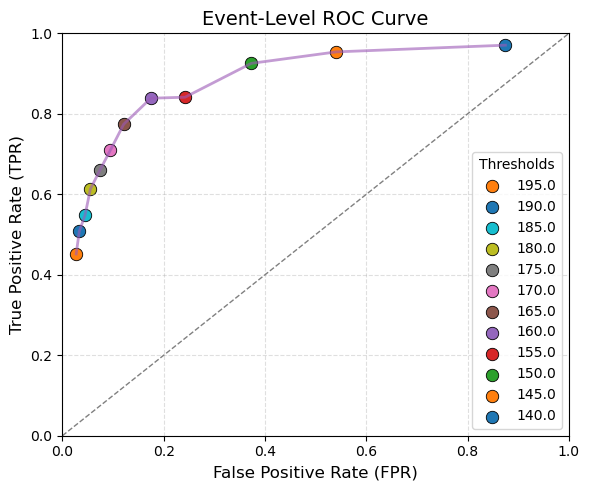

In [7]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(6, 5))

plt.plot(
    thresholds["FPR"],
    thresholds["TPR"],
    color="#9b59b6",
    linewidth=2,
    alpha=0.6
)

for idx, row in thresholds.iterrows():
    plt.scatter(
        row["FPR"],
        row["TPR"],
        color=f"C{idx}",
        s=80,
        edgecolor="black",
        linewidth=0.6,
        label=f"{row['Threshold']}"
    )

# Diagonal baseline
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', linewidth=1)

plt.xlabel("False Positive Rate (FPR)", fontsize=12)
plt.ylabel("True Positive Rate (TPR)", fontsize=12)
plt.title("Event-Level ROC Curve", fontsize=14)

plt.grid(True, linestyle='--', alpha=0.4)
plt.xlim(0, 1)
plt.ylim(0, 1)

# Legend outside the plot
plt.legend(
    loc="lower right",
    bbox_to_anchor=(1, 0),
    title="Thresholds"
)


plt.tight_layout()
plt.show()


## Create Images & Export to CNN_Snips

#########################   Category a     ###########################
Filename: 671633444.190702140024.wav


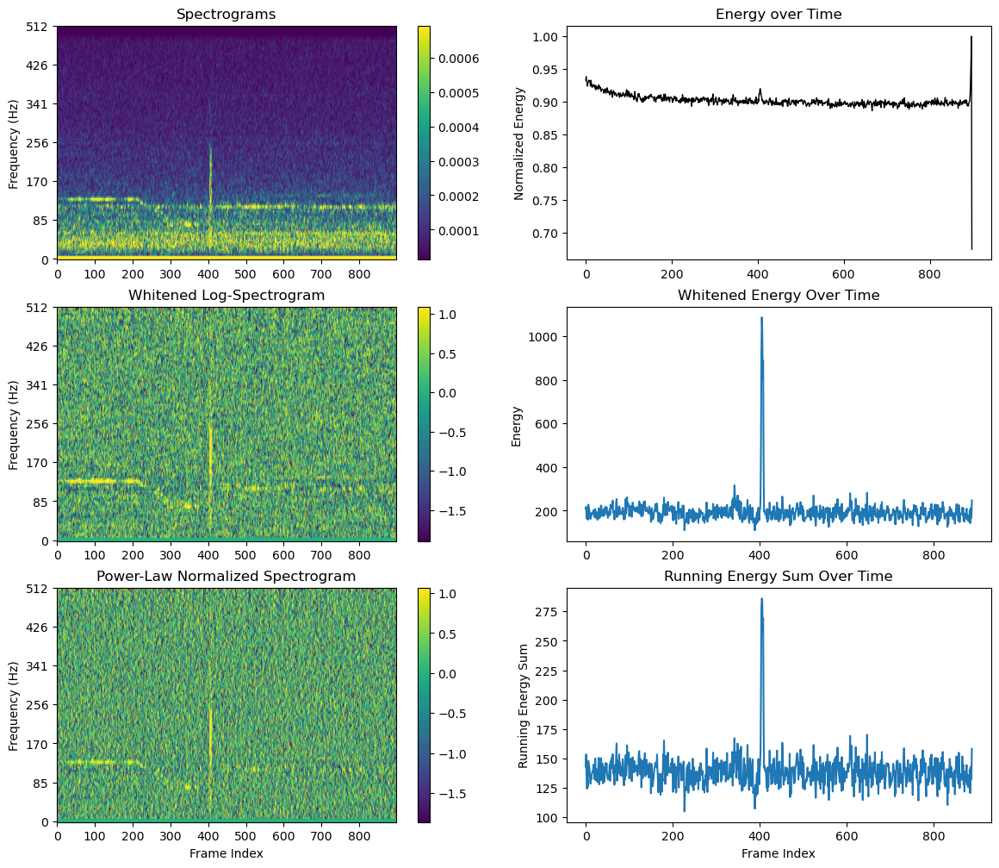

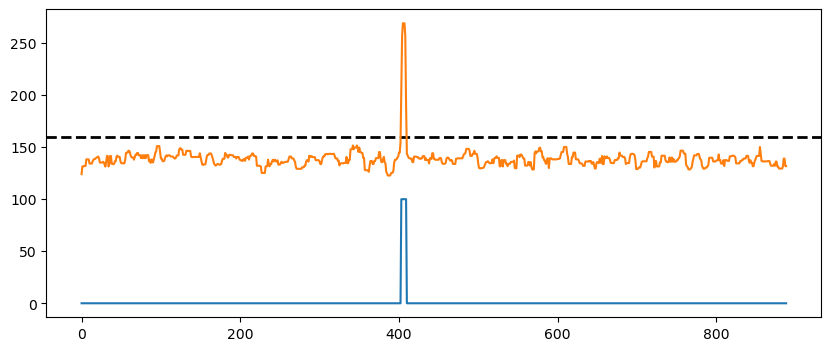

Filename: 1208221730.181207000246.wav


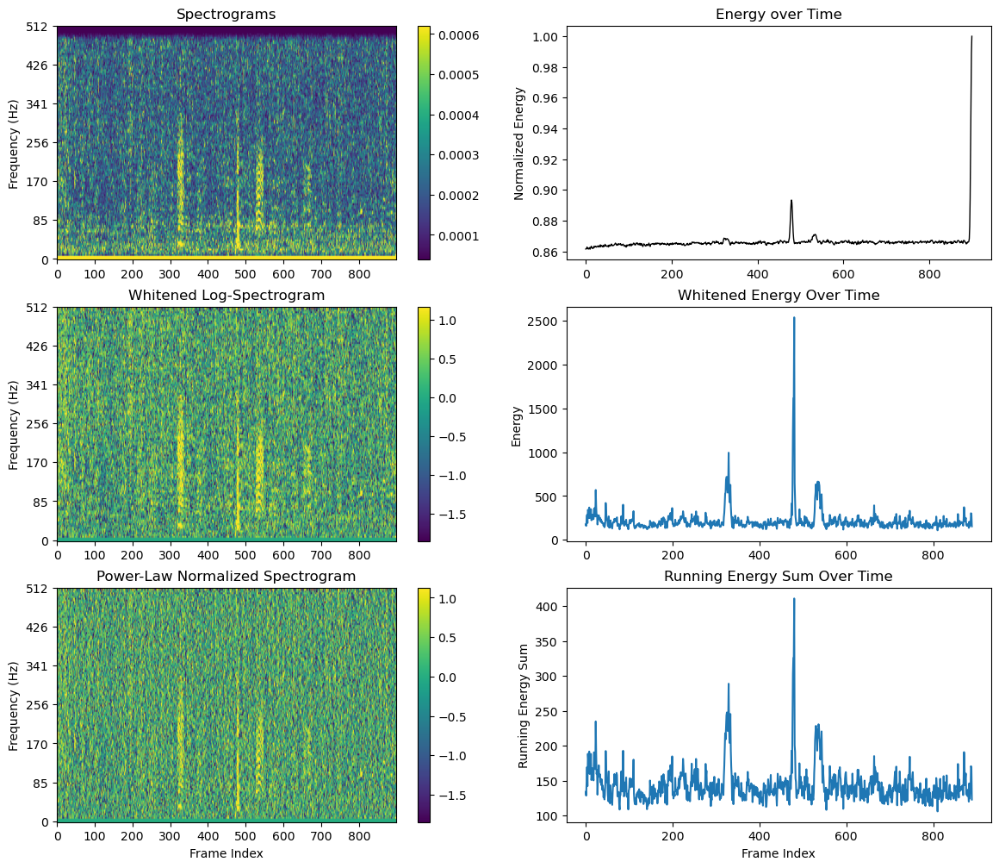

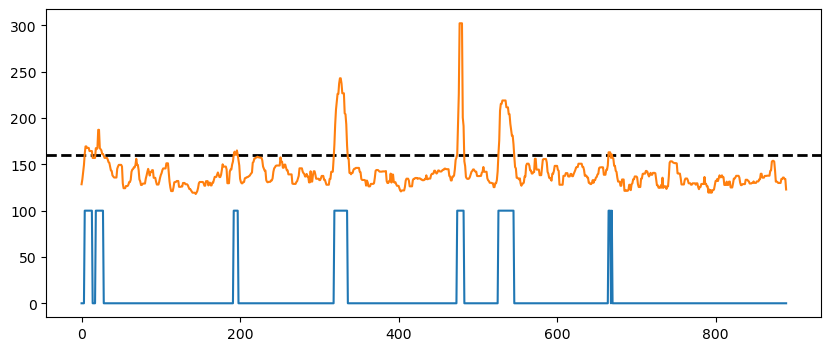

Filename: 1208221730.181207002246.wav


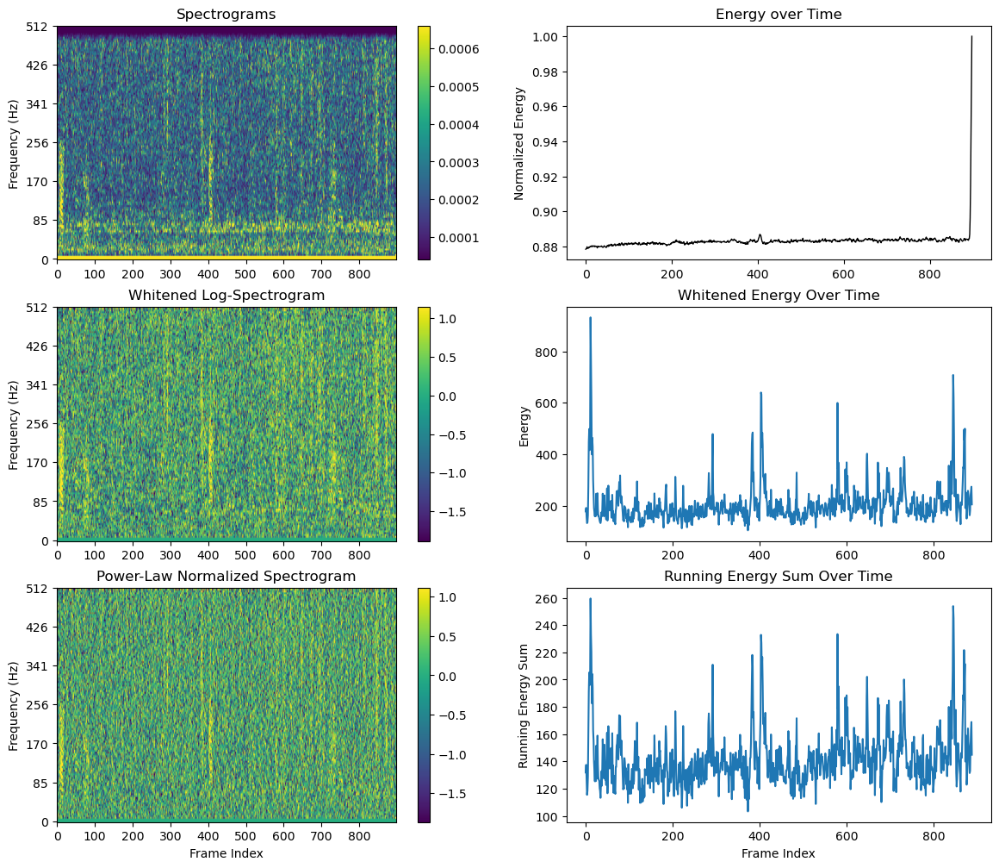

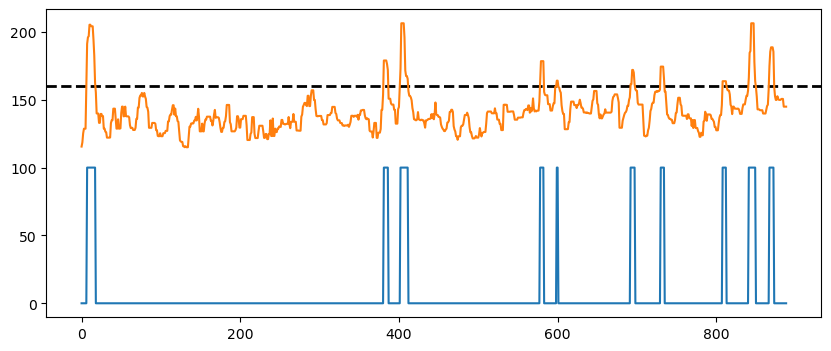

Filename: 1208221730.181207024246.wav


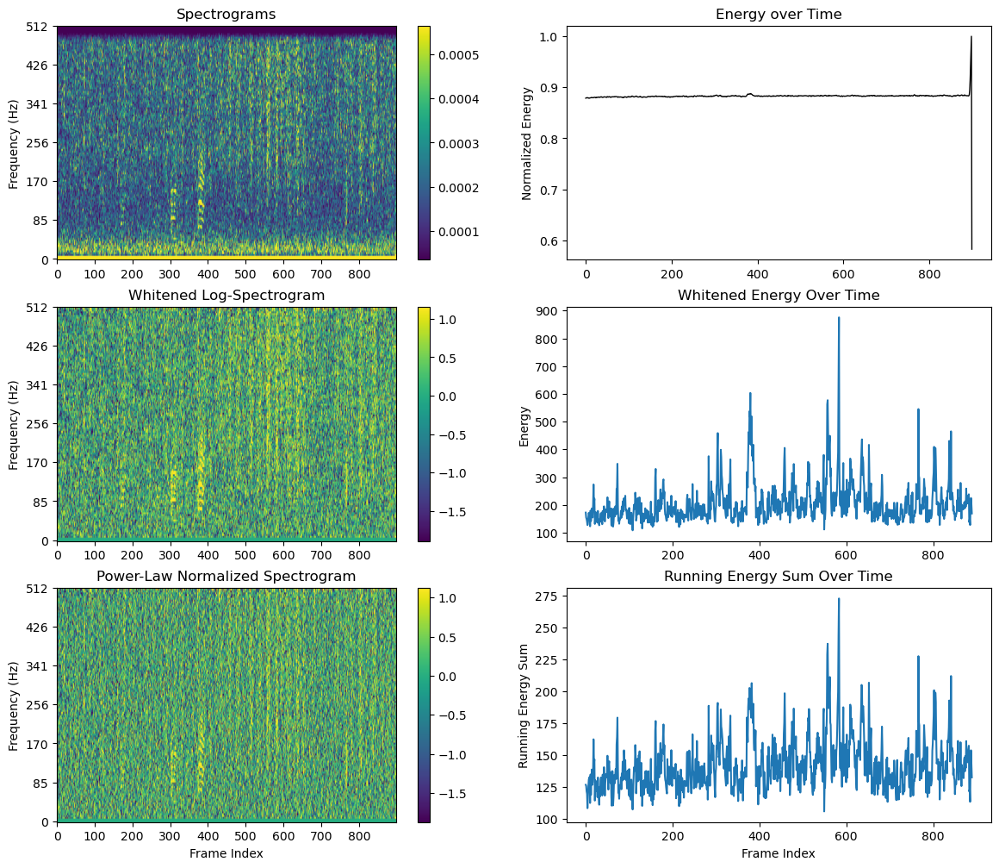

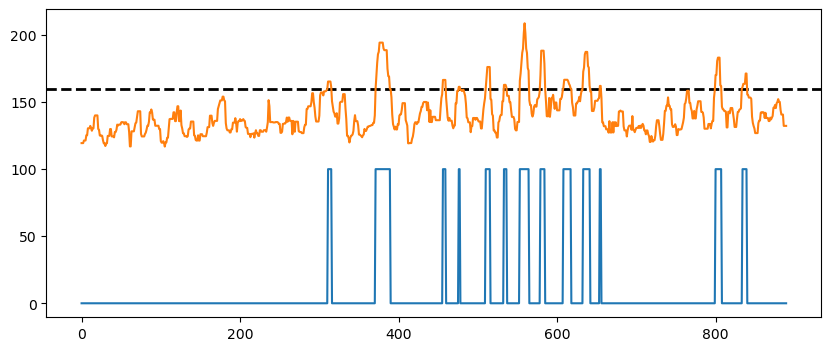

Filename: 1208221730.181207162246.wav


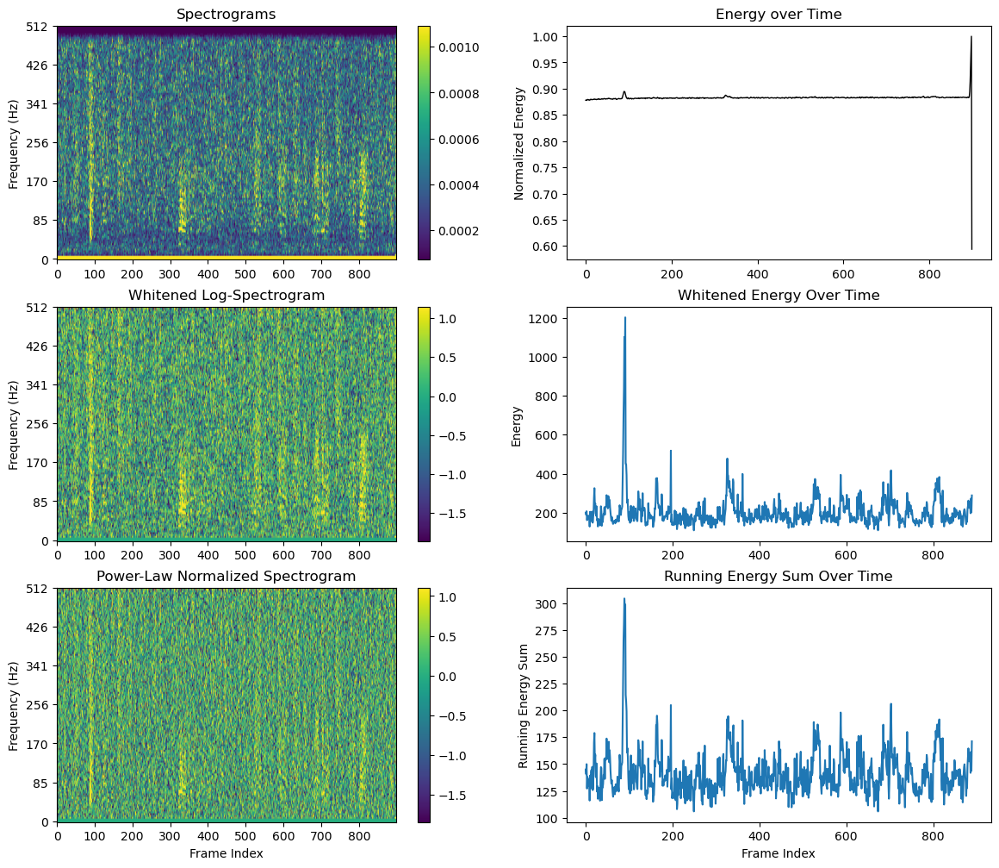

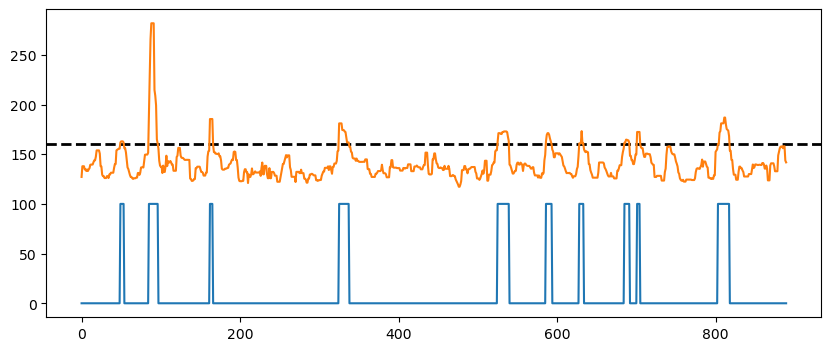

Filename: 1208221730.181207182246.wav


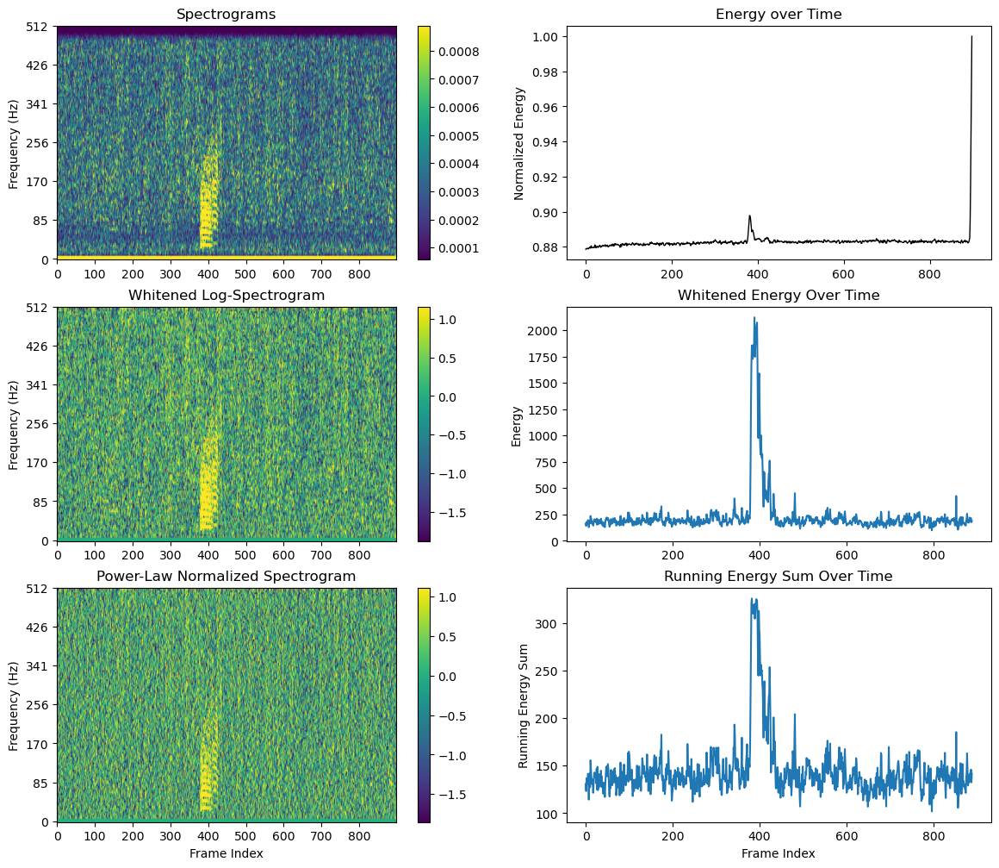

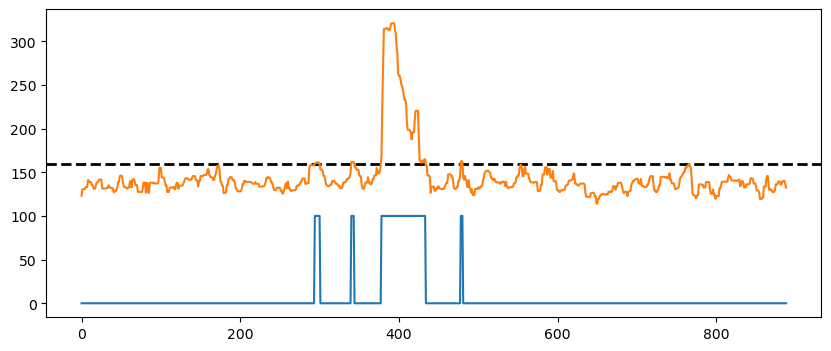

Filename: 1208221730.181207214246.wav


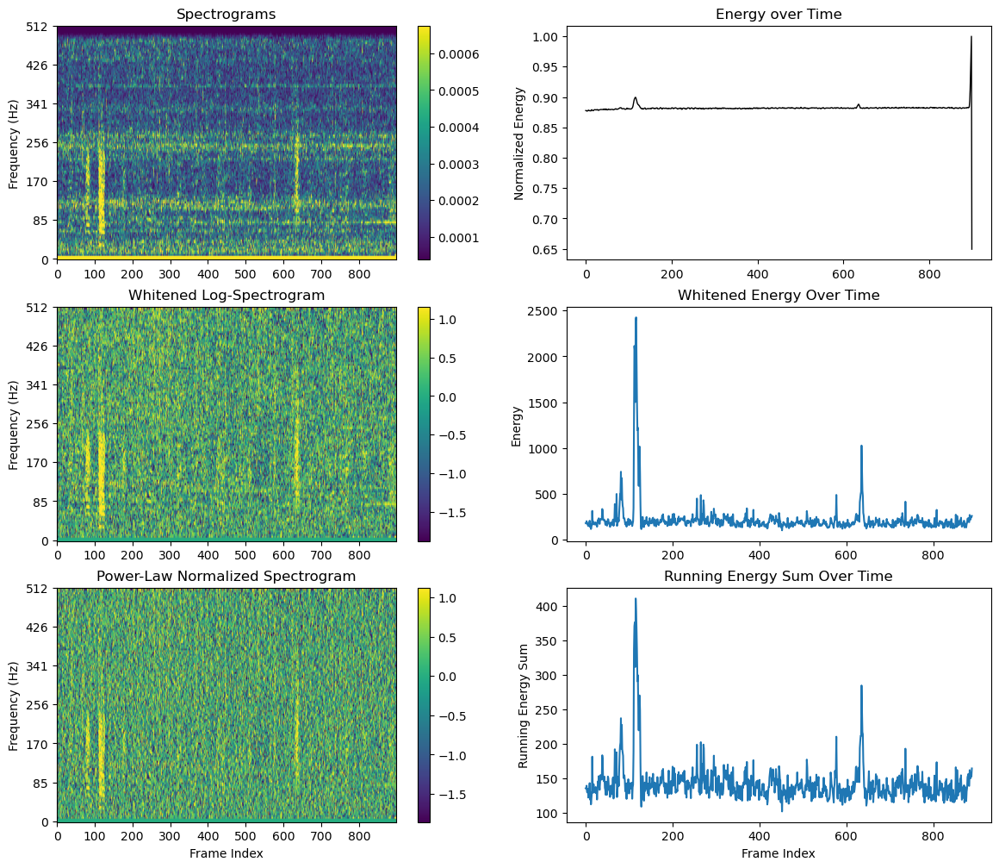

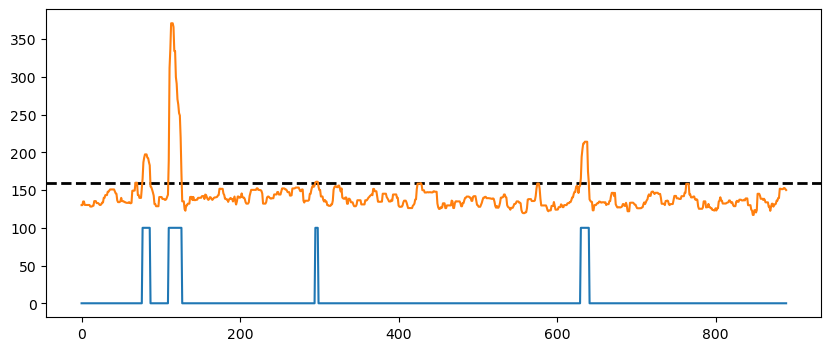

Filename: 1208221730.181207222246.wav


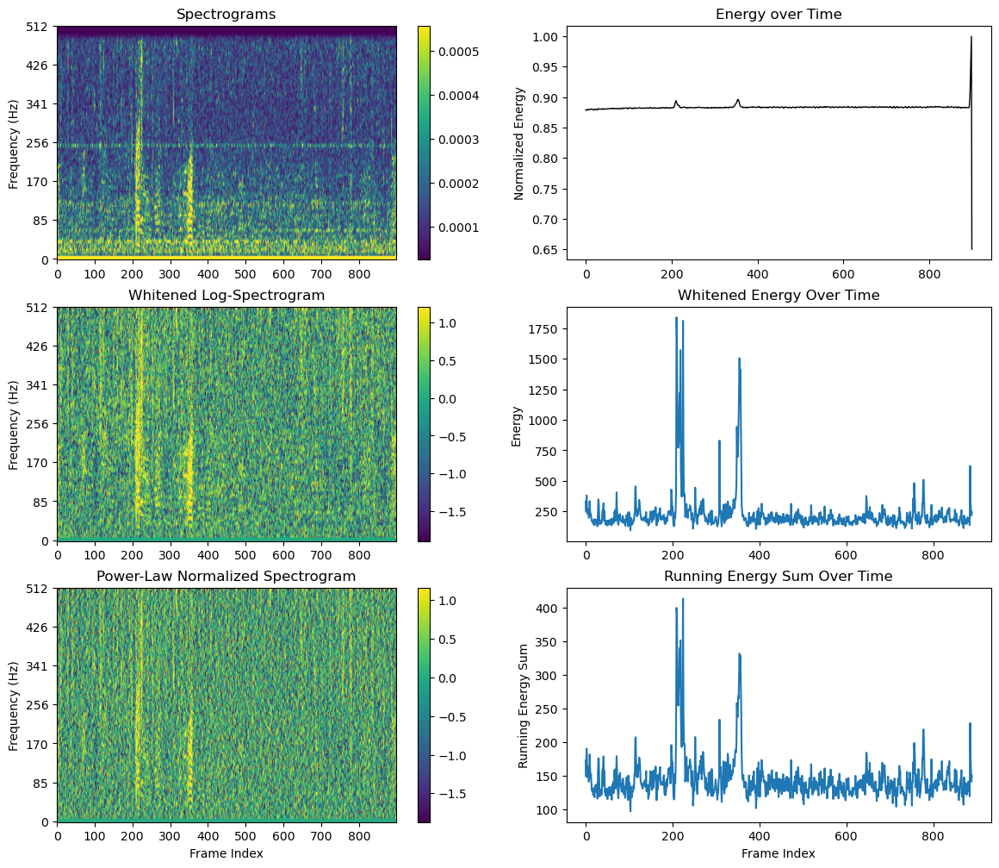

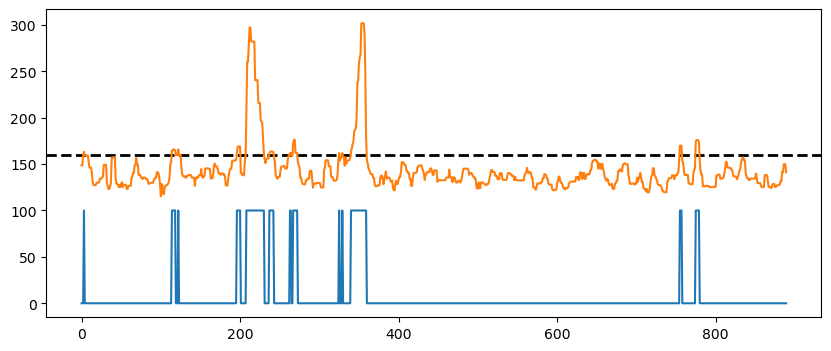

Filename: 1208221730.181207232246.wav


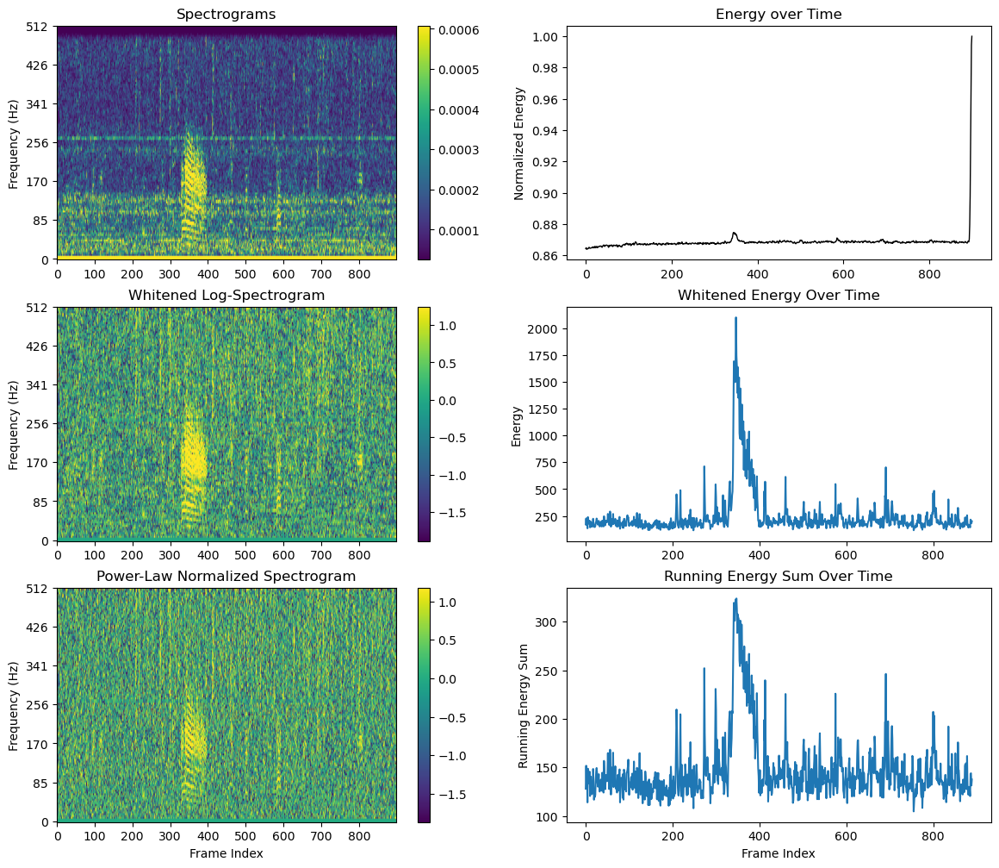

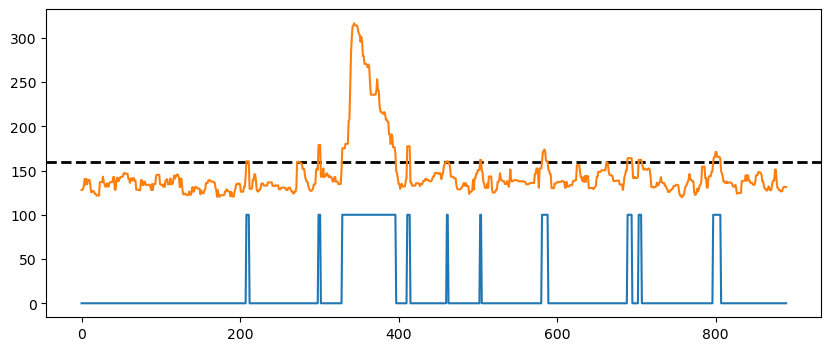

Filename: 1208221730.181207234246.wav


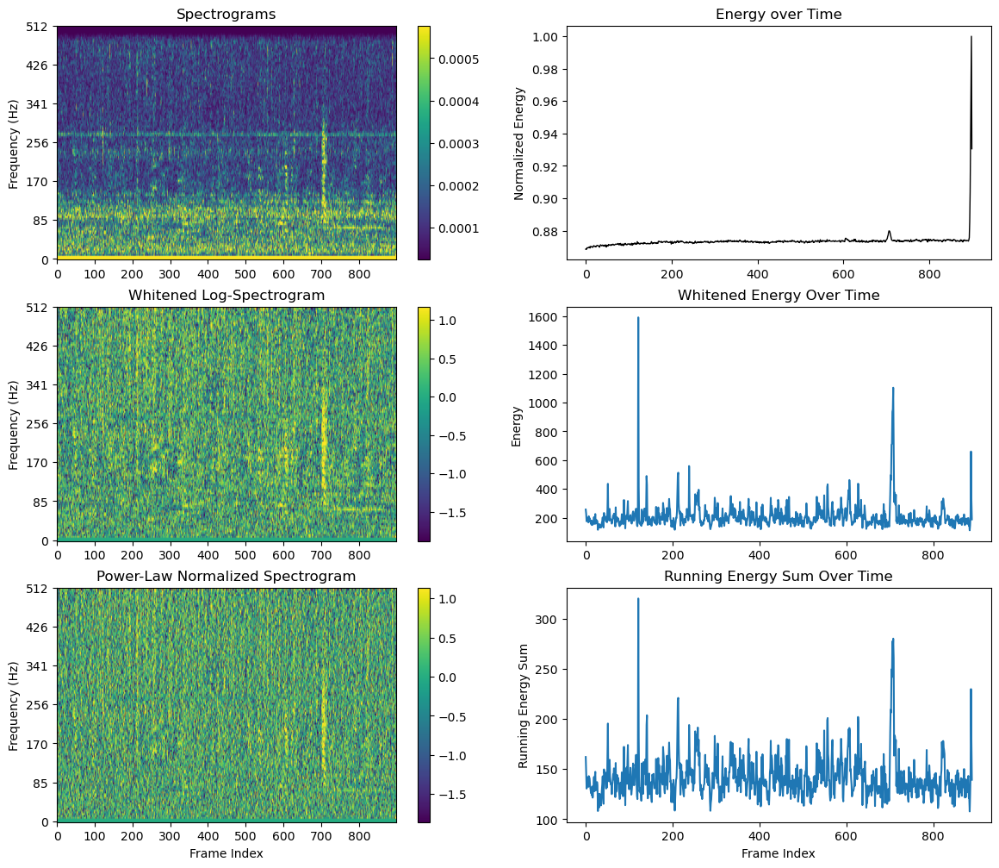

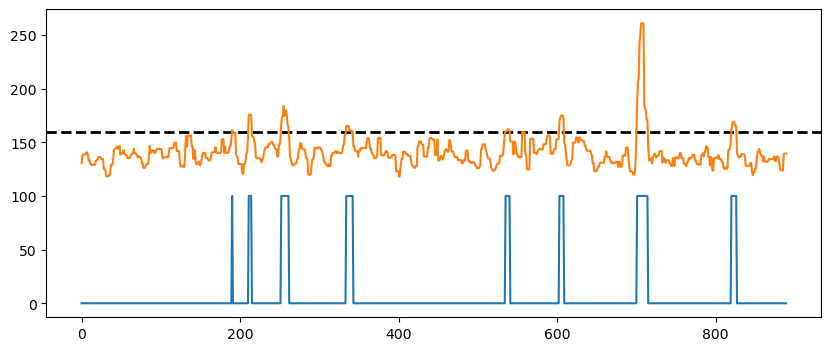

Filename: 1677774874.191211000615.wav


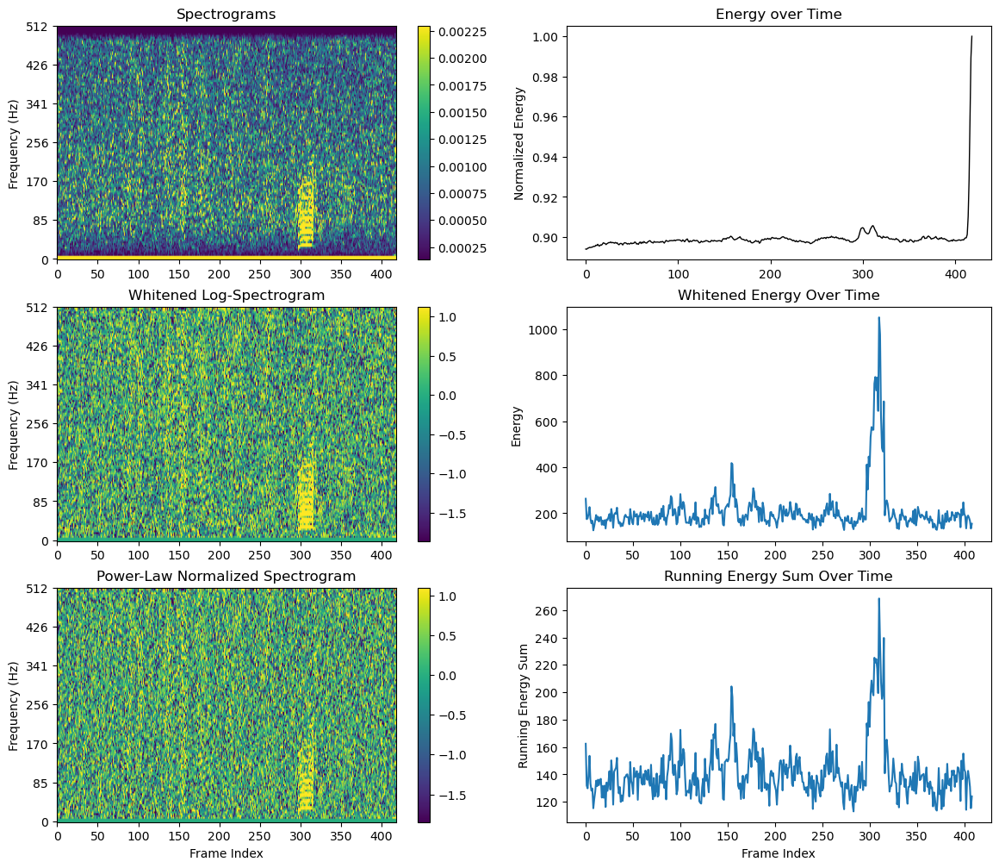

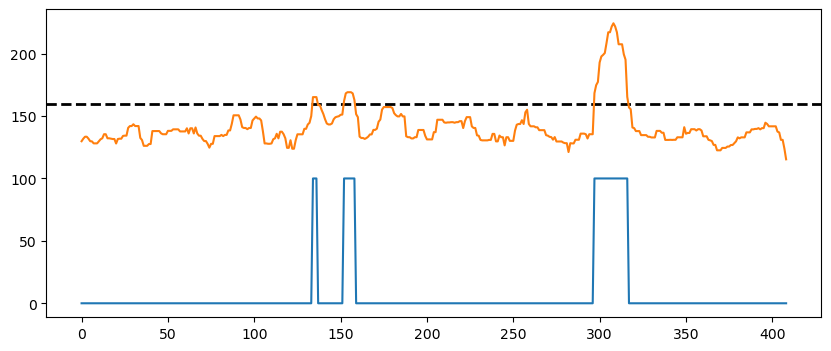

Filename: 1677774874.191211045615.wav


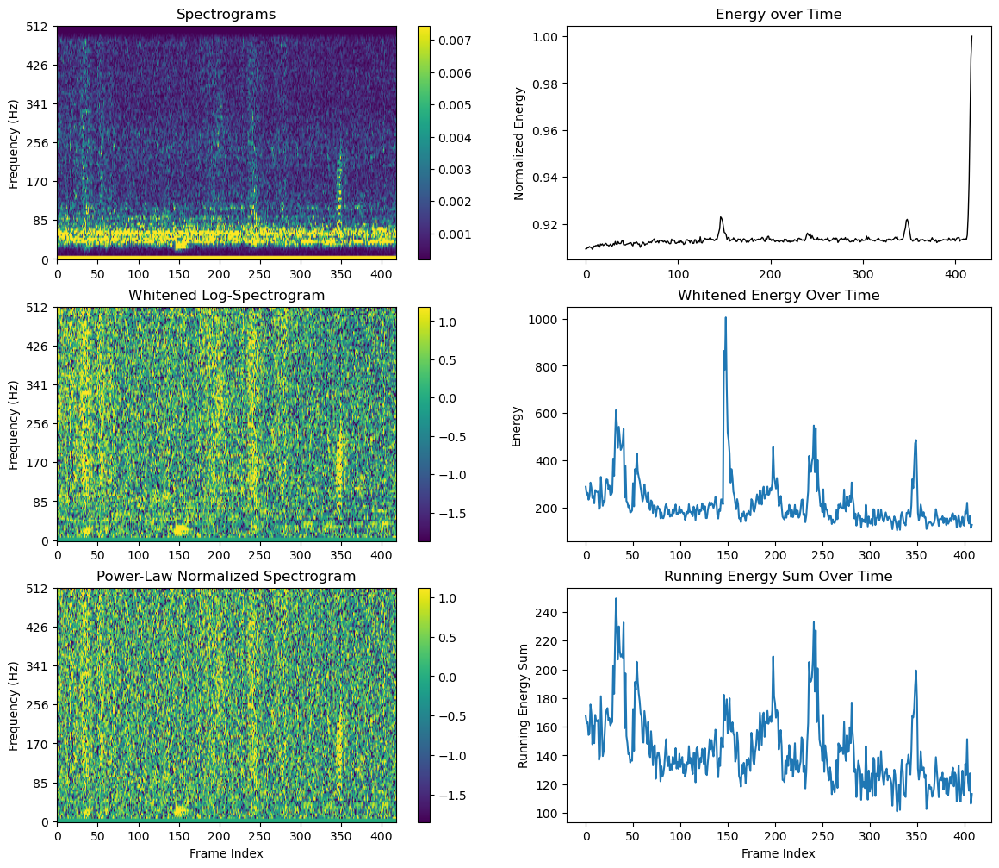

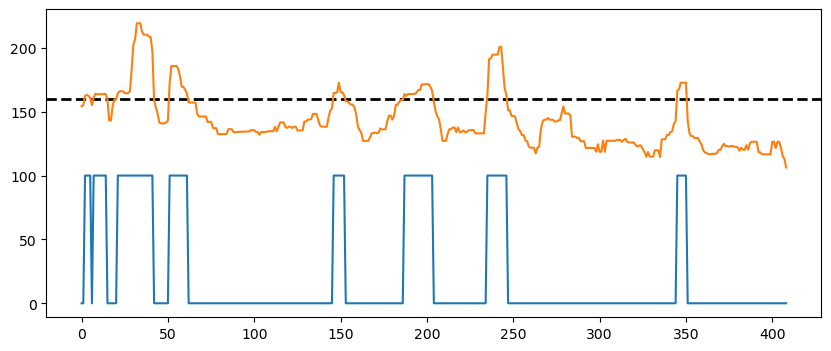

Filename: 1677774874.191211224615.wav


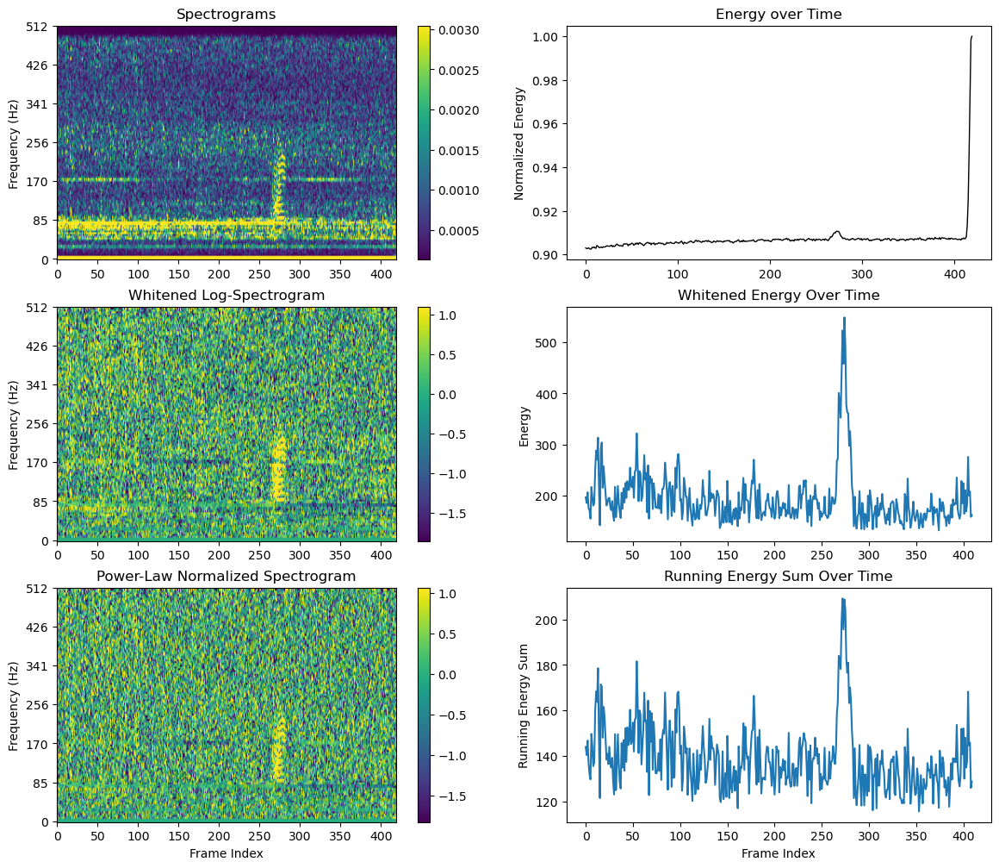

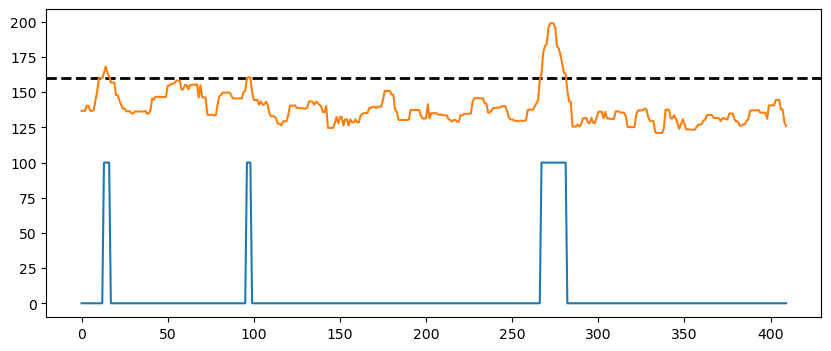

Filename: 1677774874.200209000615.wav


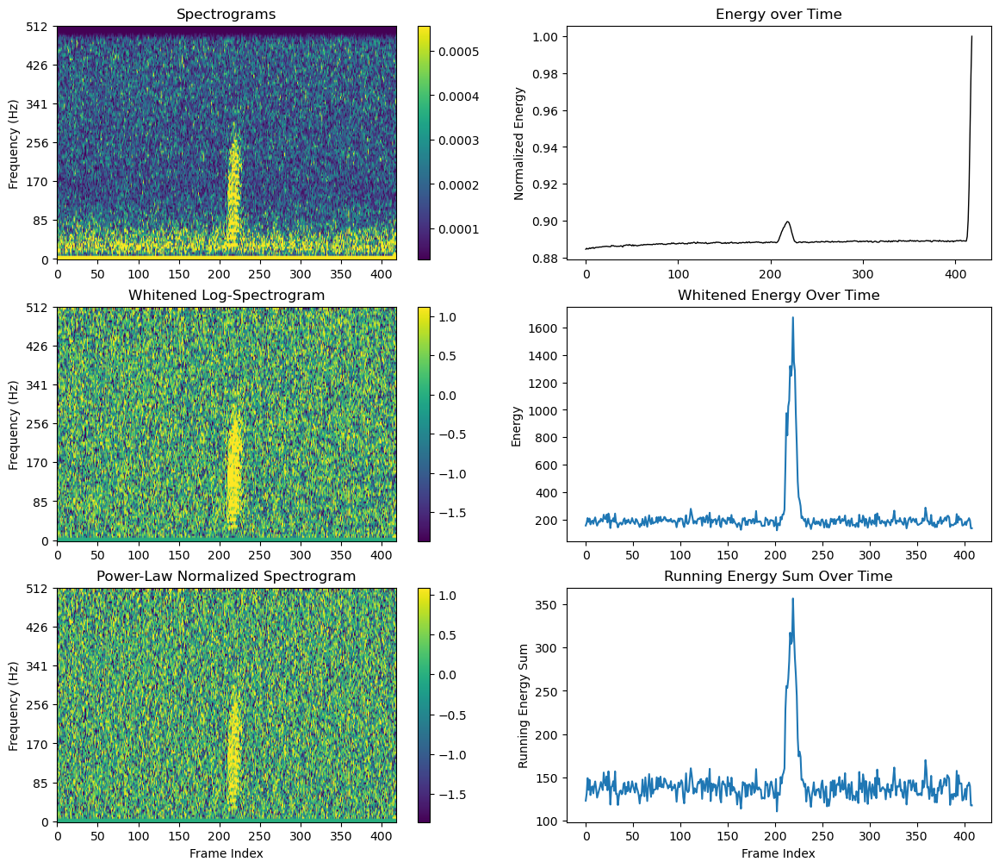

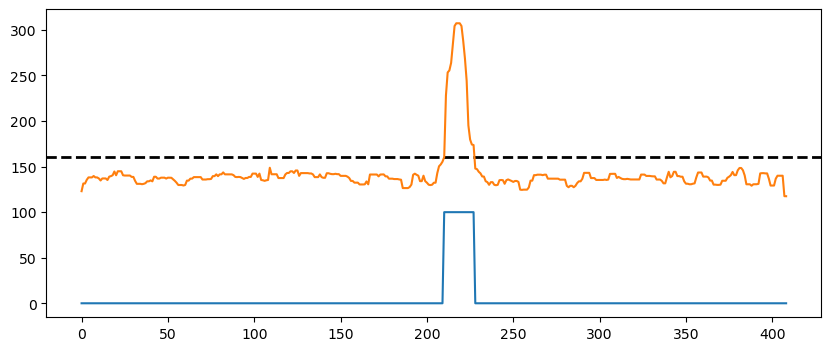

Filename: 1208221730.181207034246.wav


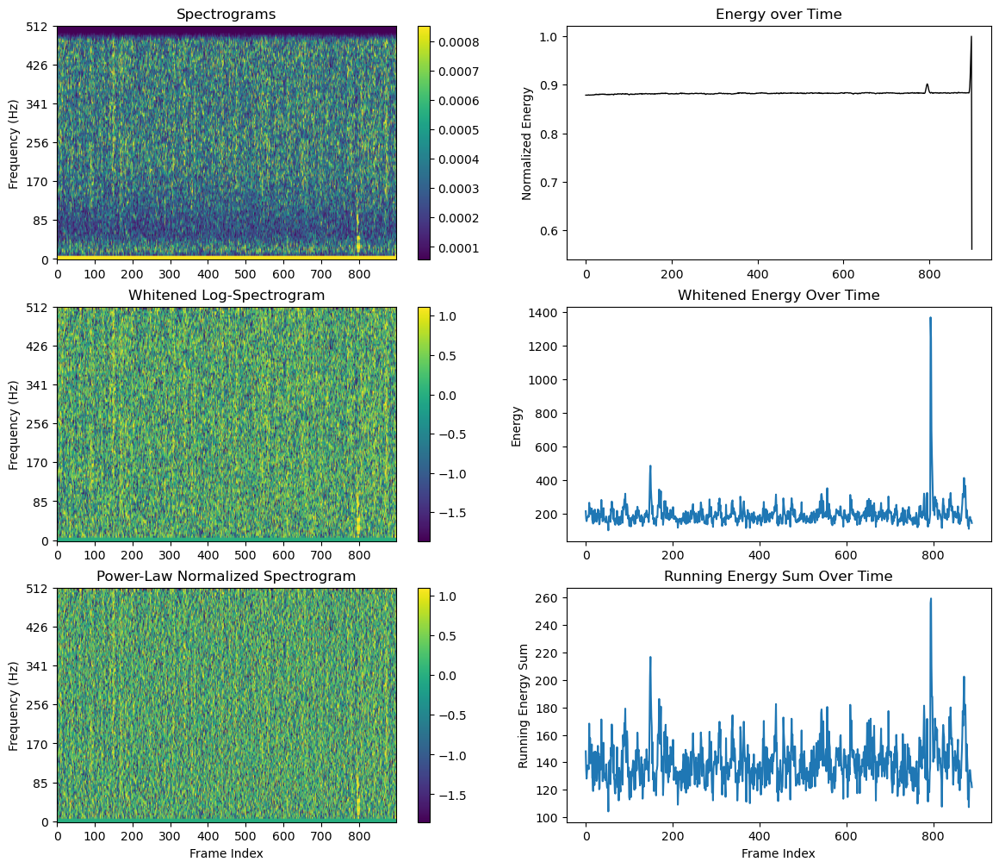

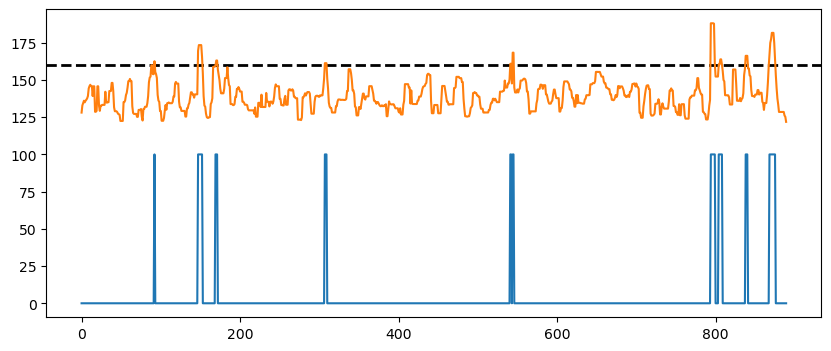

#########################   Category b     ###########################
Filename: 671633444.190518024024.wav


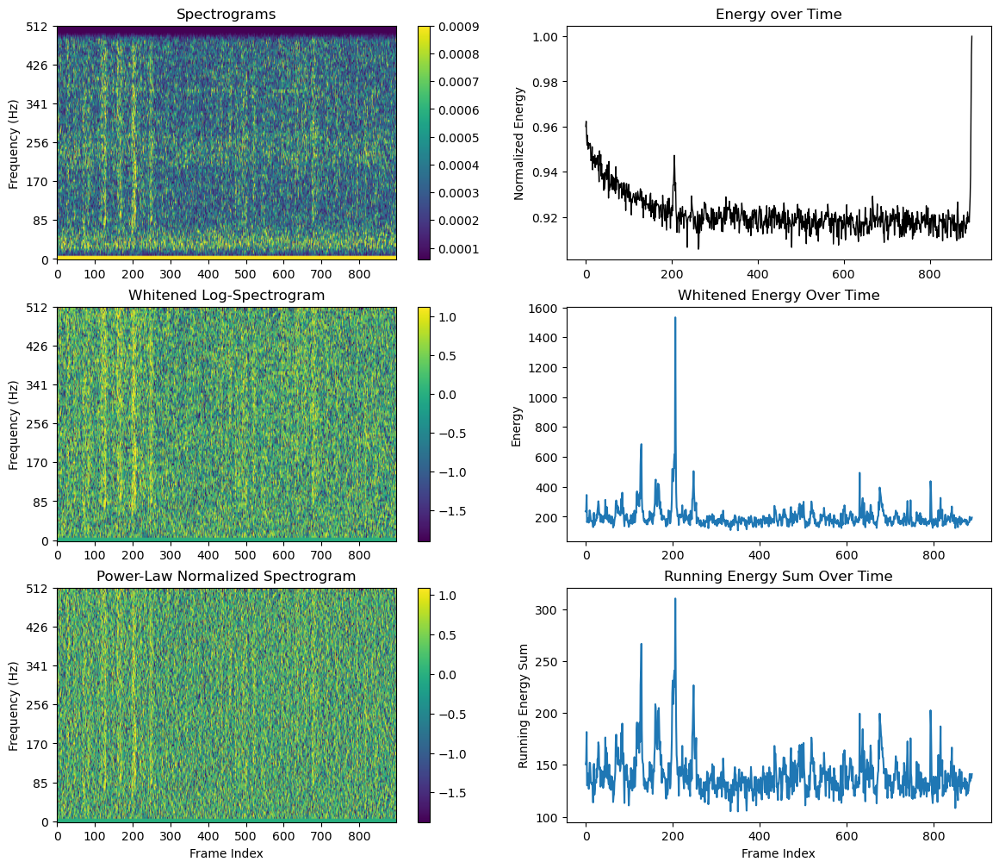

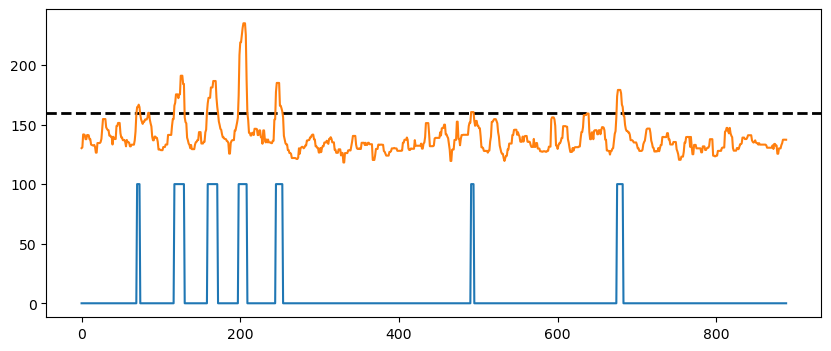

Filename: 671633444.190617160024.wav


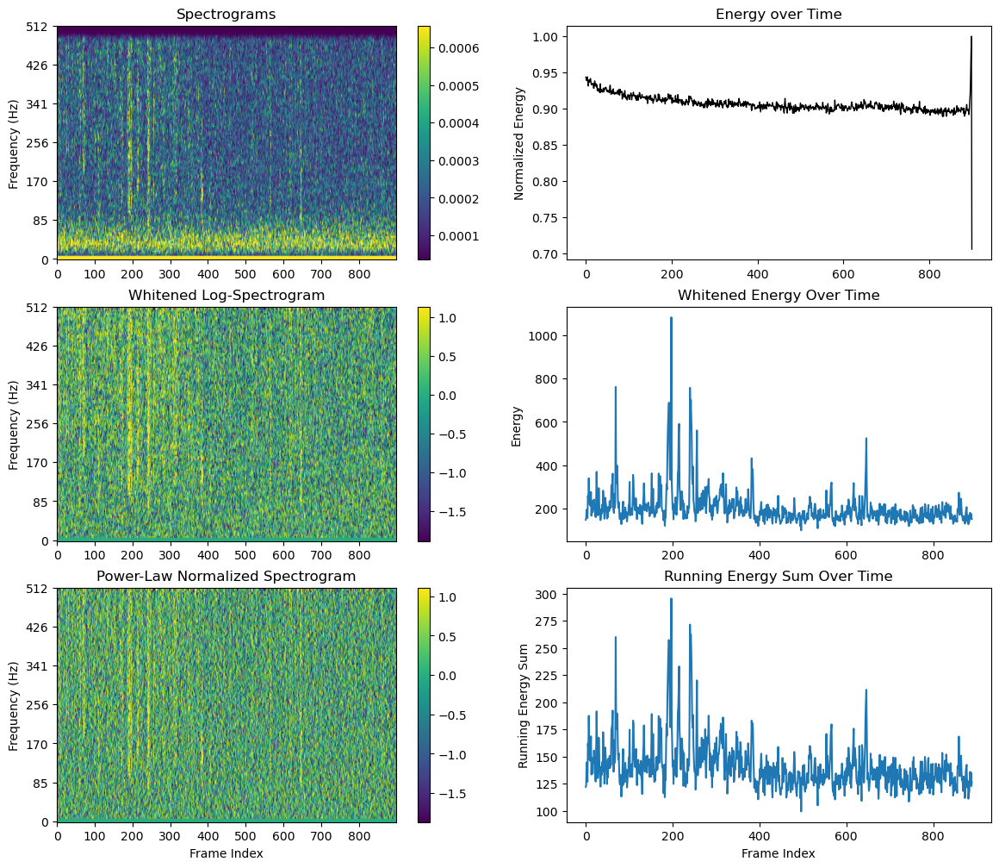

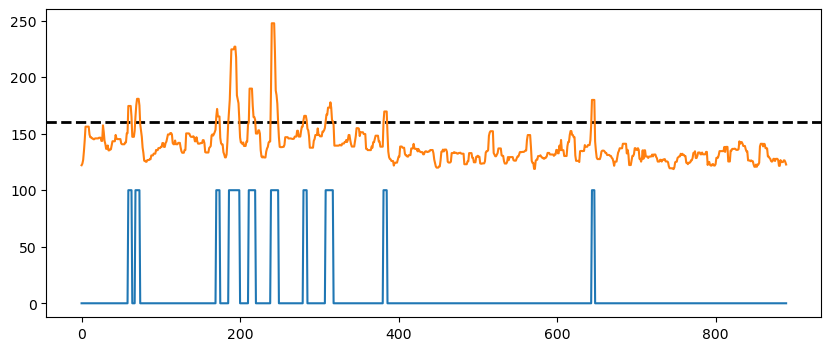

Filename: 671633444.190617163024.wav


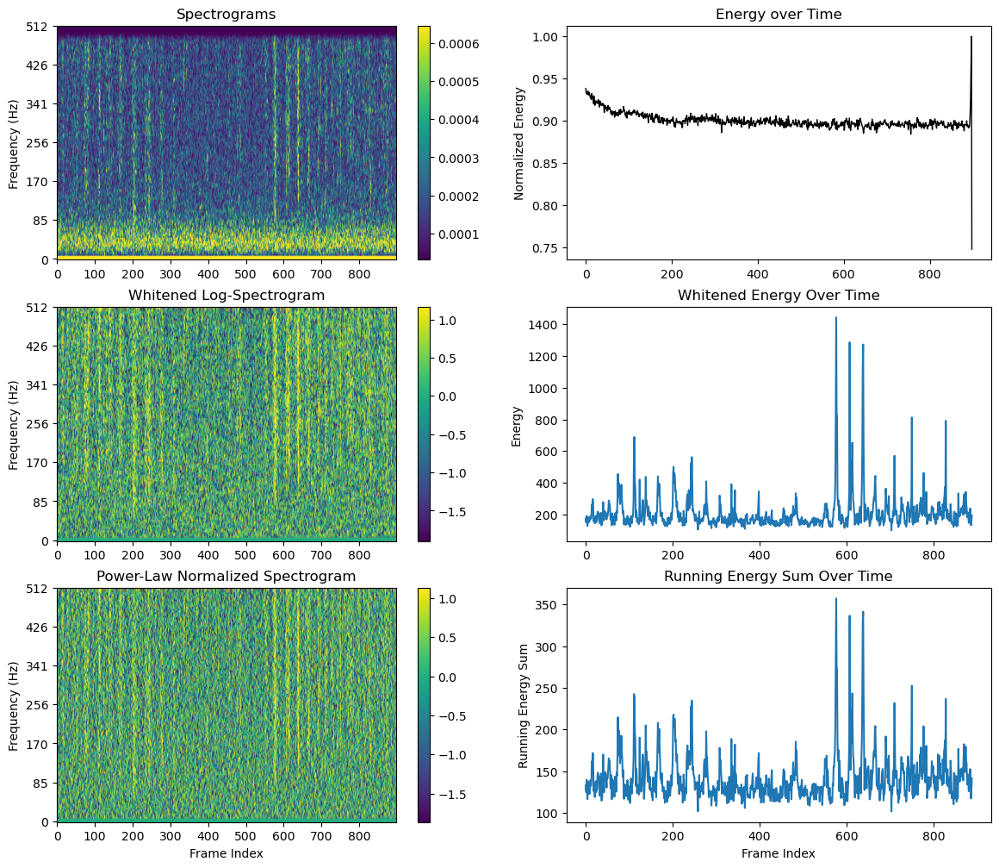

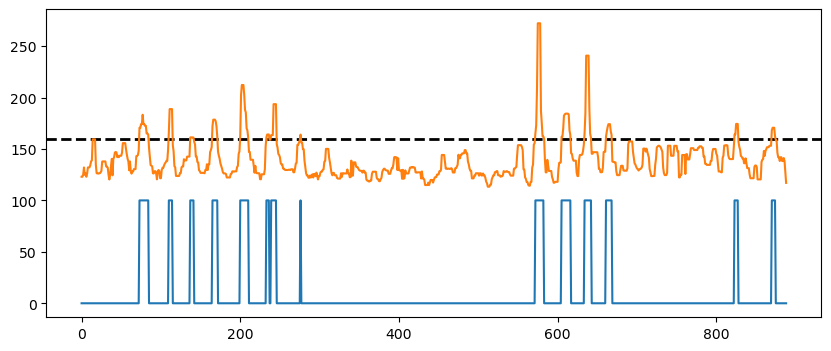

Filename: 671633444.190702032024.wav


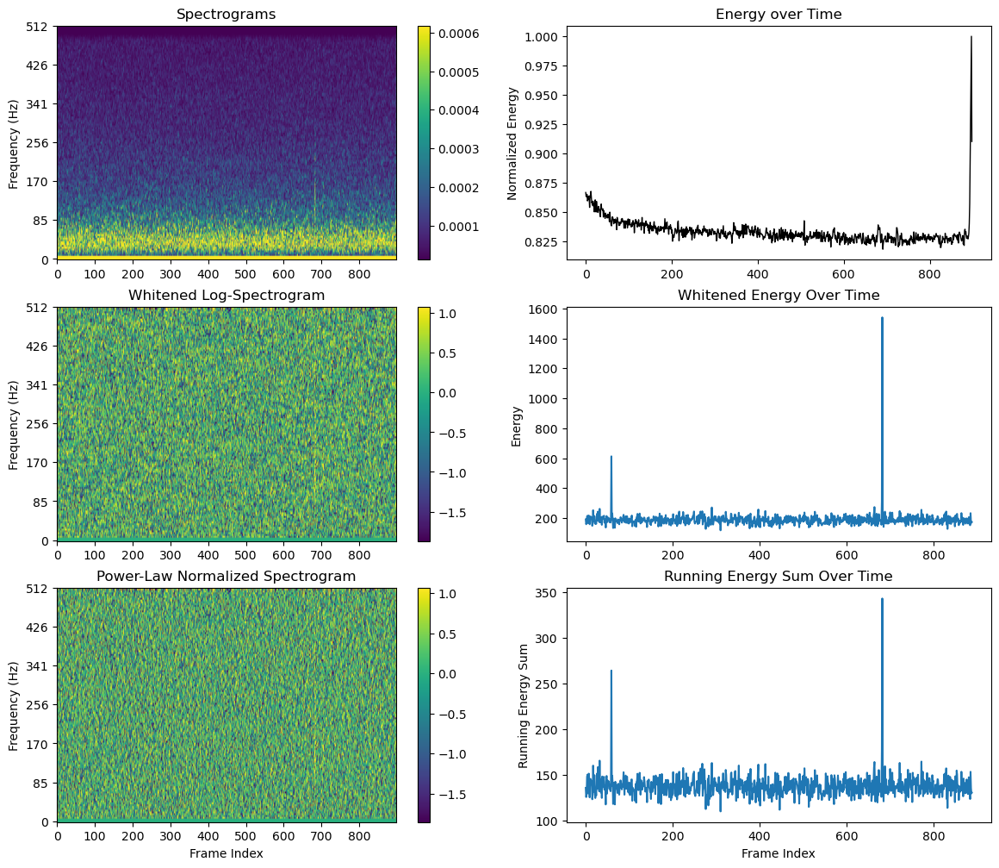

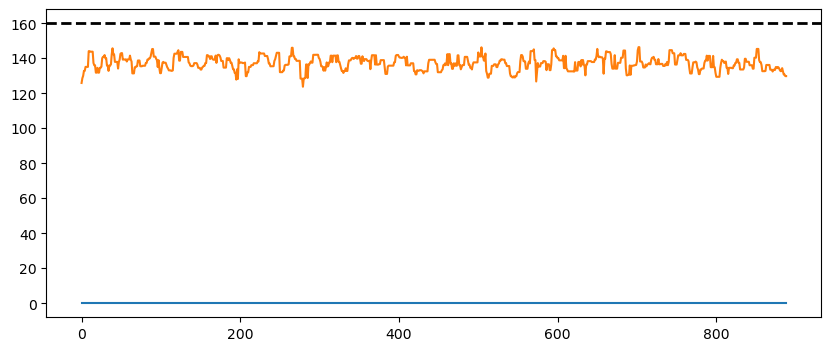

Filename: 1208221730.190320040246.wav


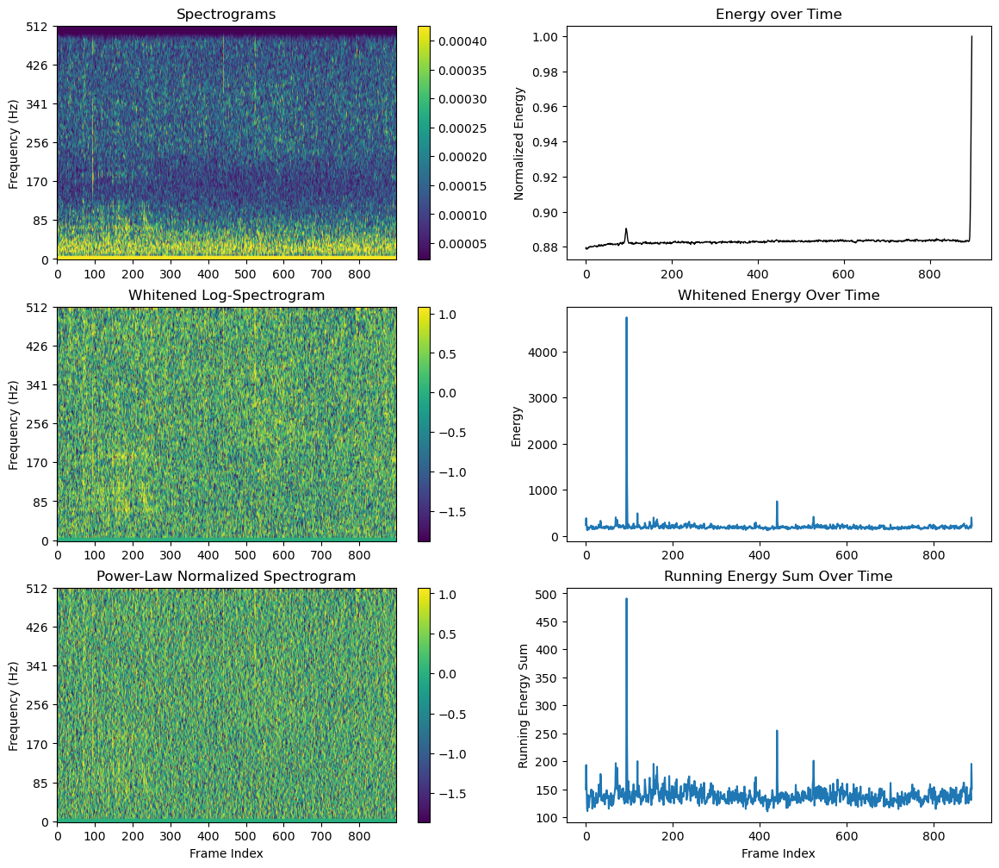

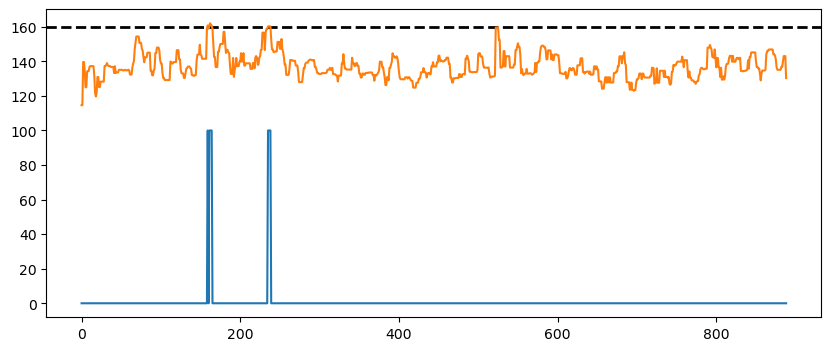

Filename: 1677774874.191126071615.wav


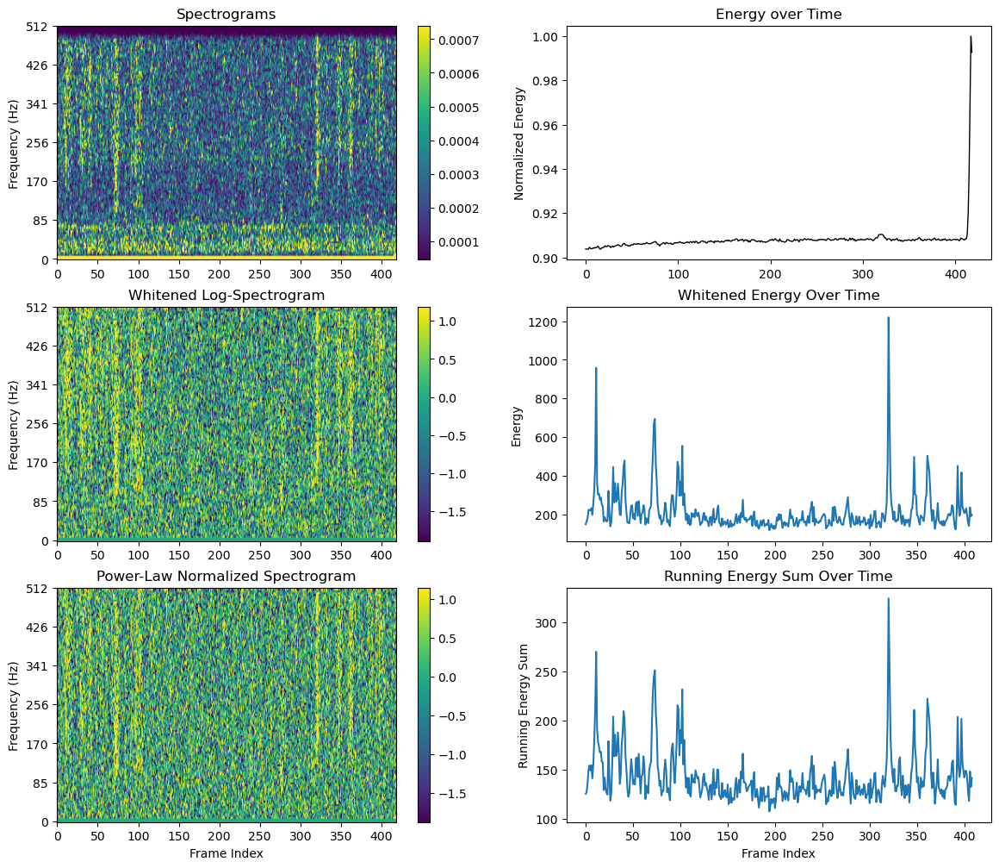

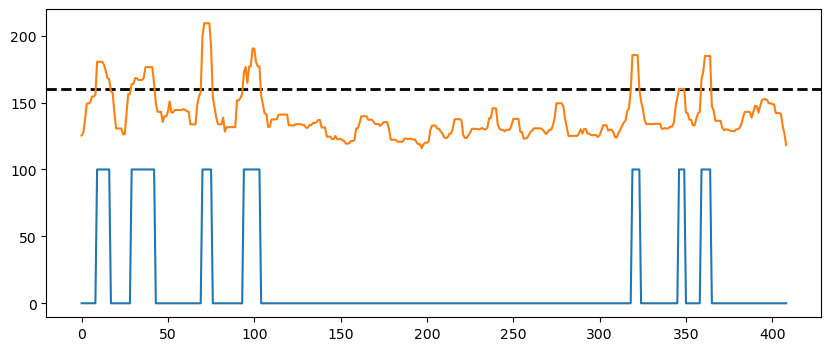

Filename: 1677774874.191126072615.wav


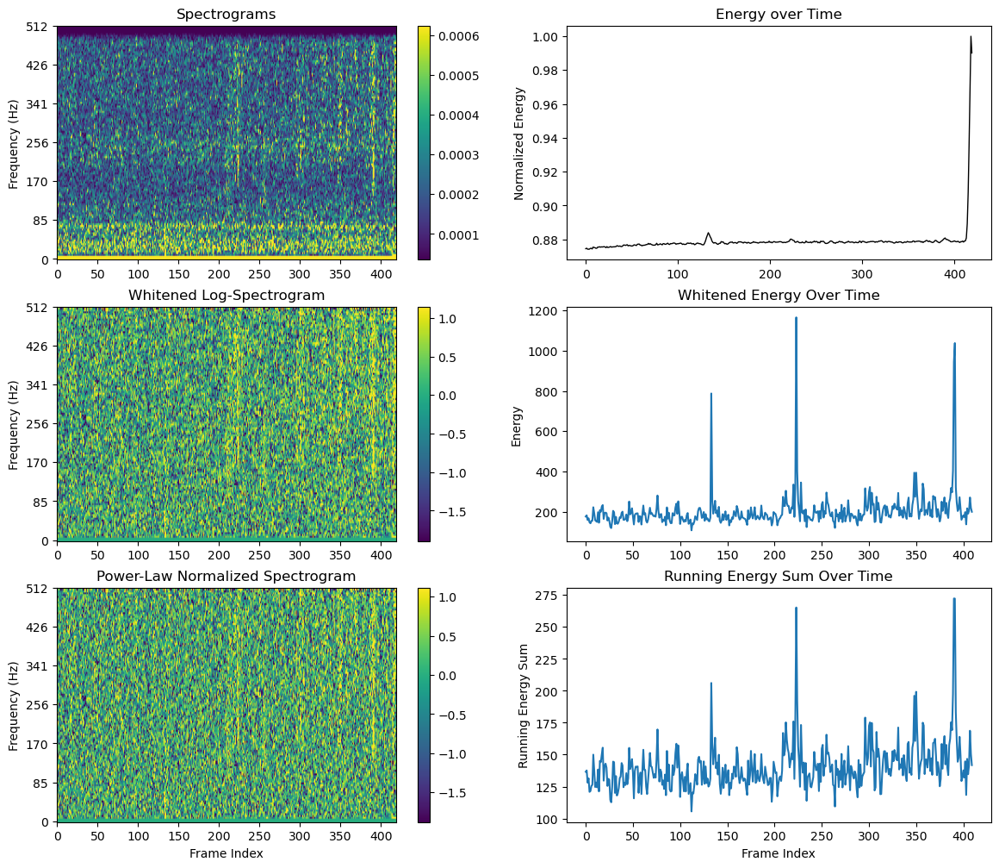

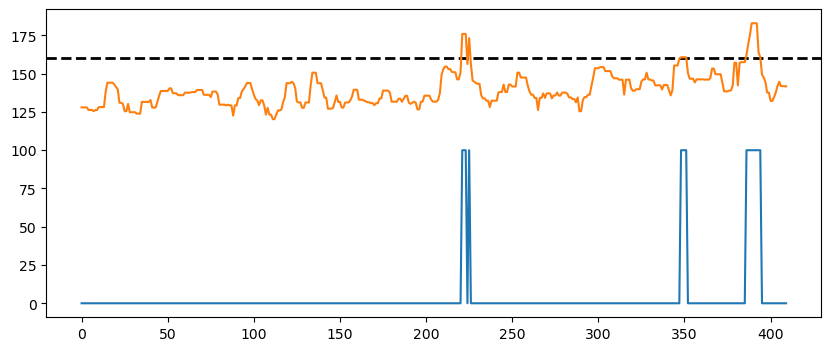

Filename: 1677774874.191225030615.wav


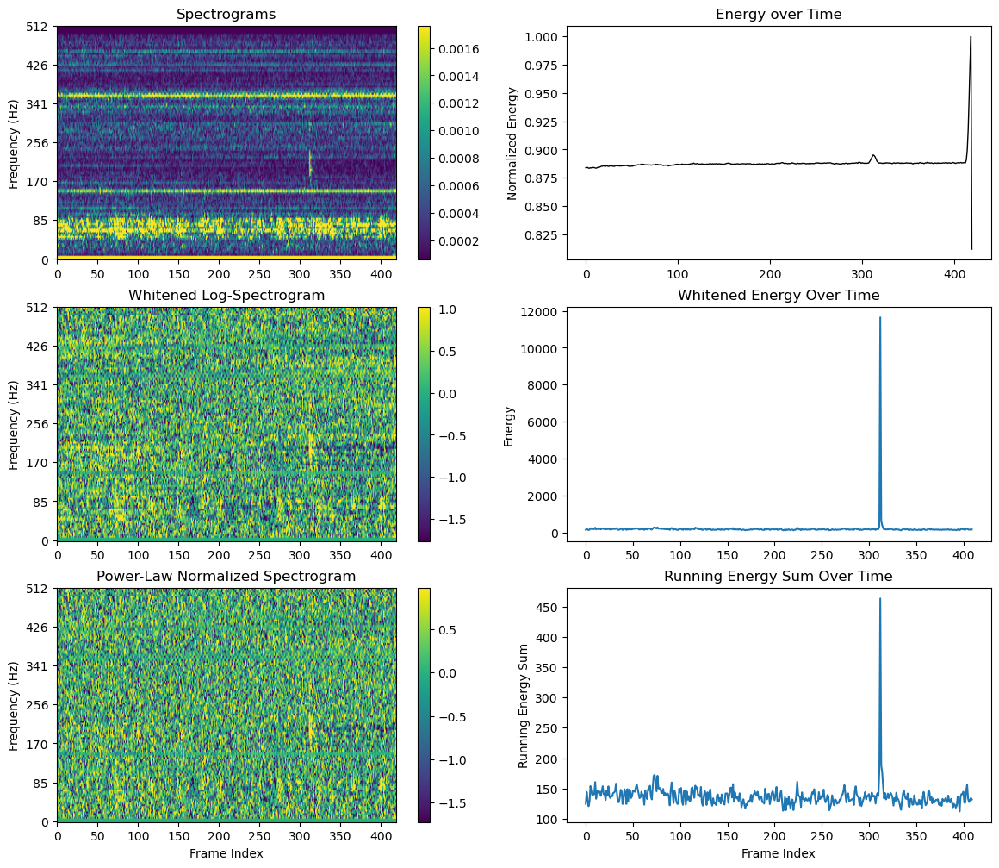

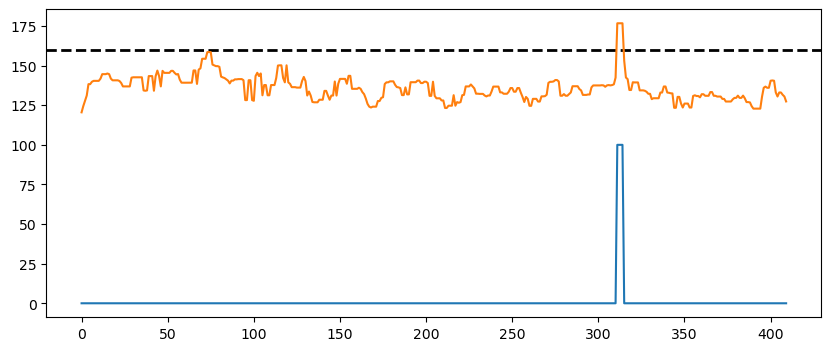

Filename: 1677774874.191225070615.wav


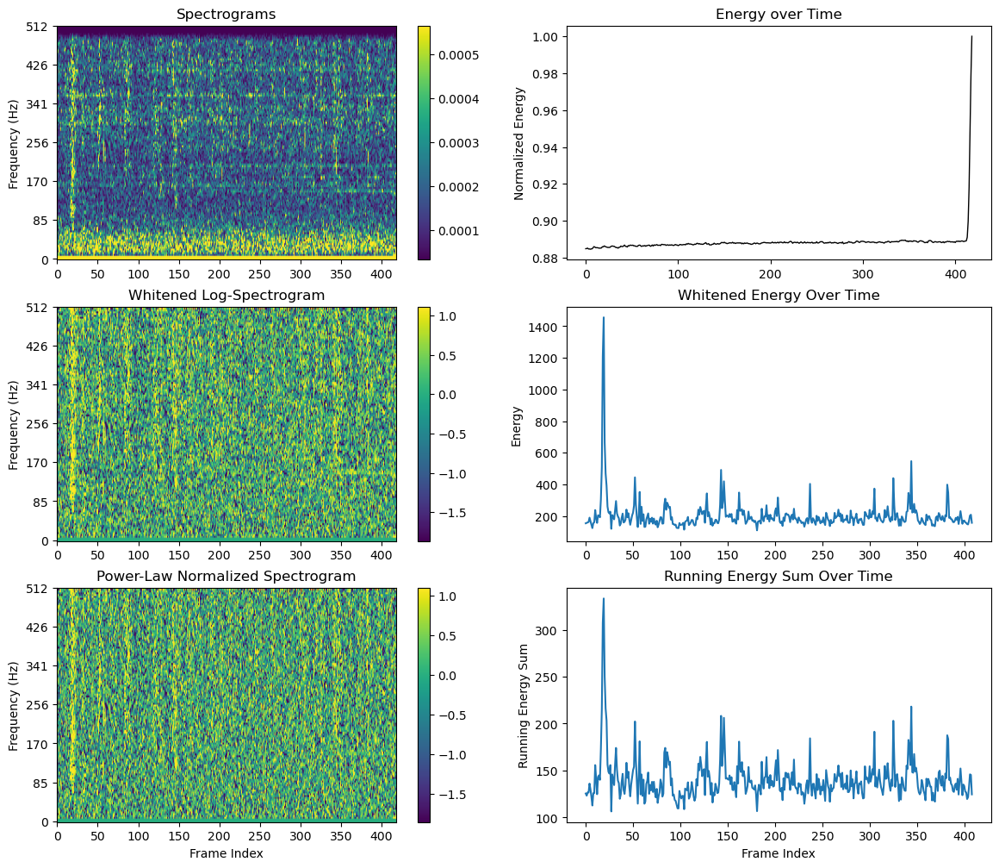

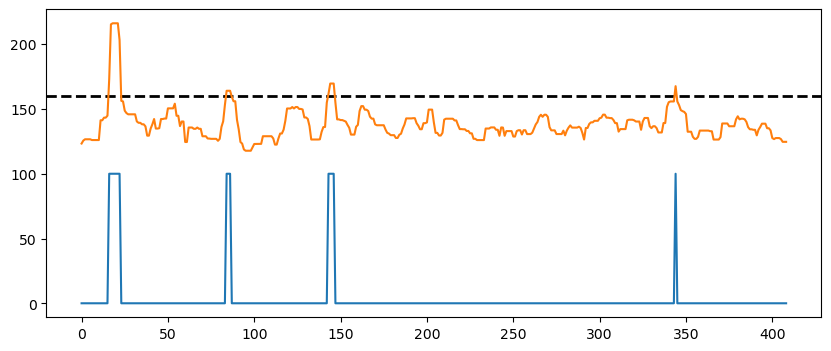

Filename: 1677774874.200309005615.wav


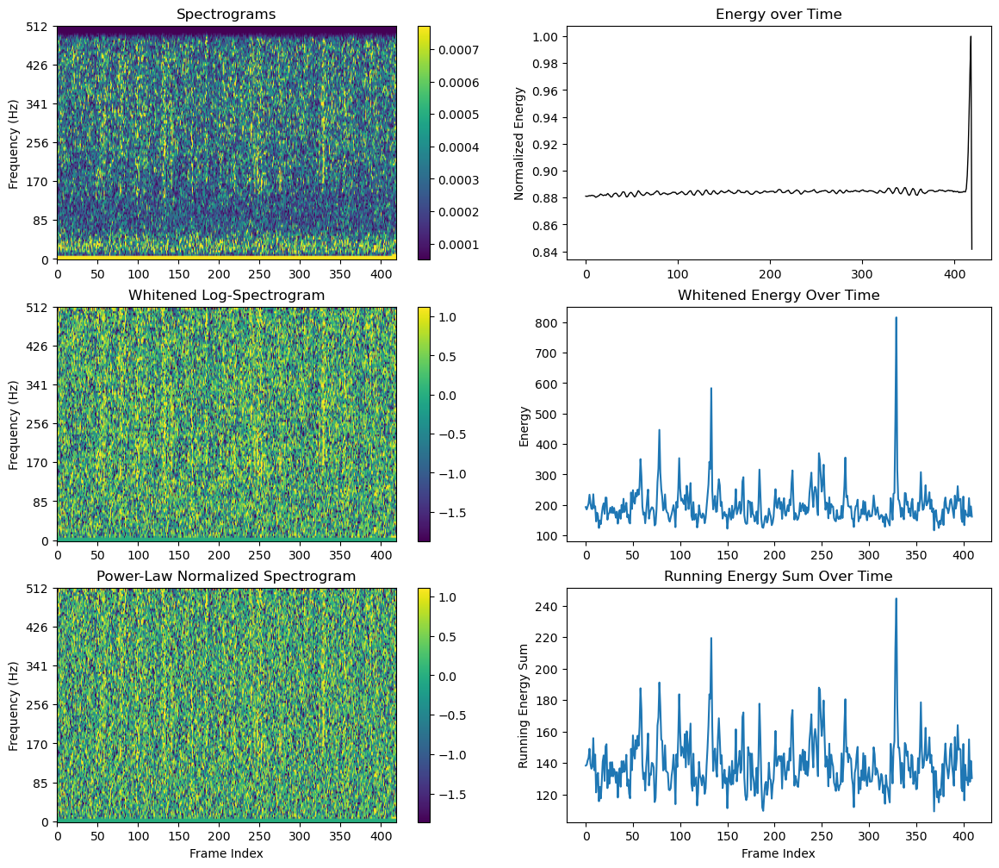

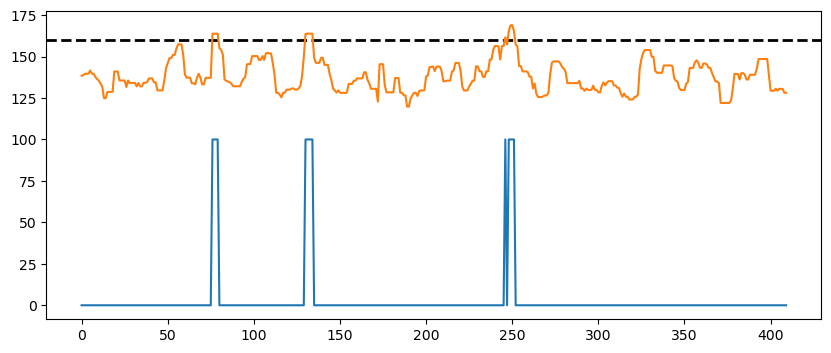

Filename: 1677774874.200309131615.wav


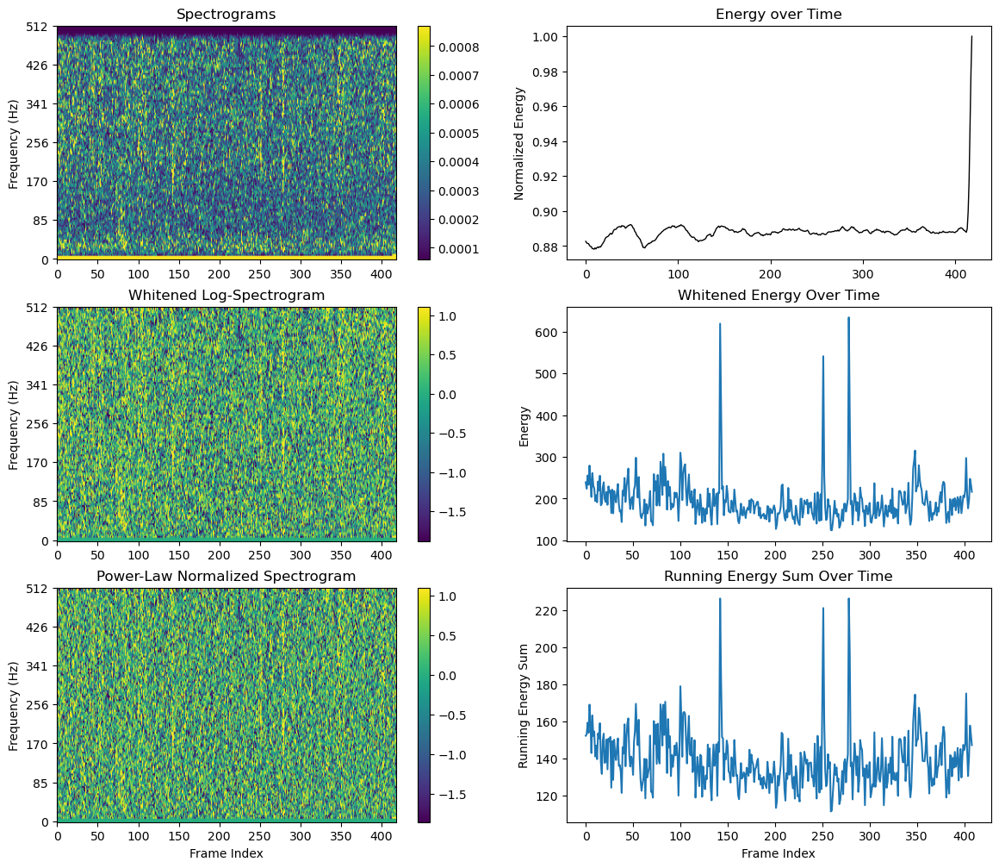

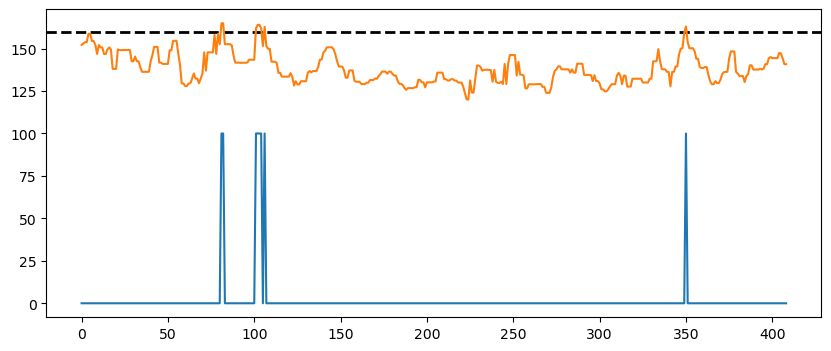

#########################   Category c     ###########################
Filename: 671633444.190702140024.wav


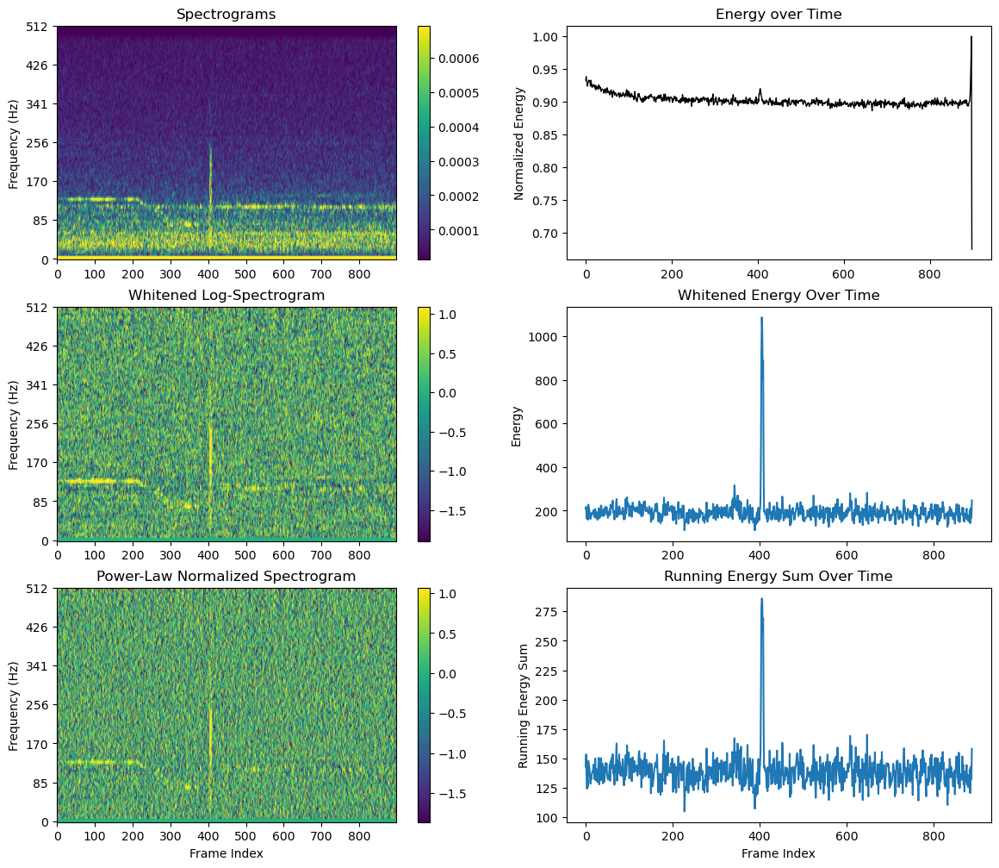

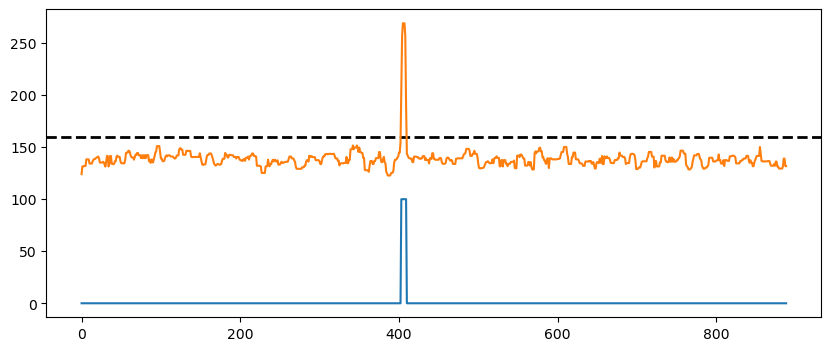

Filename: 1208221730.190501164246.wav


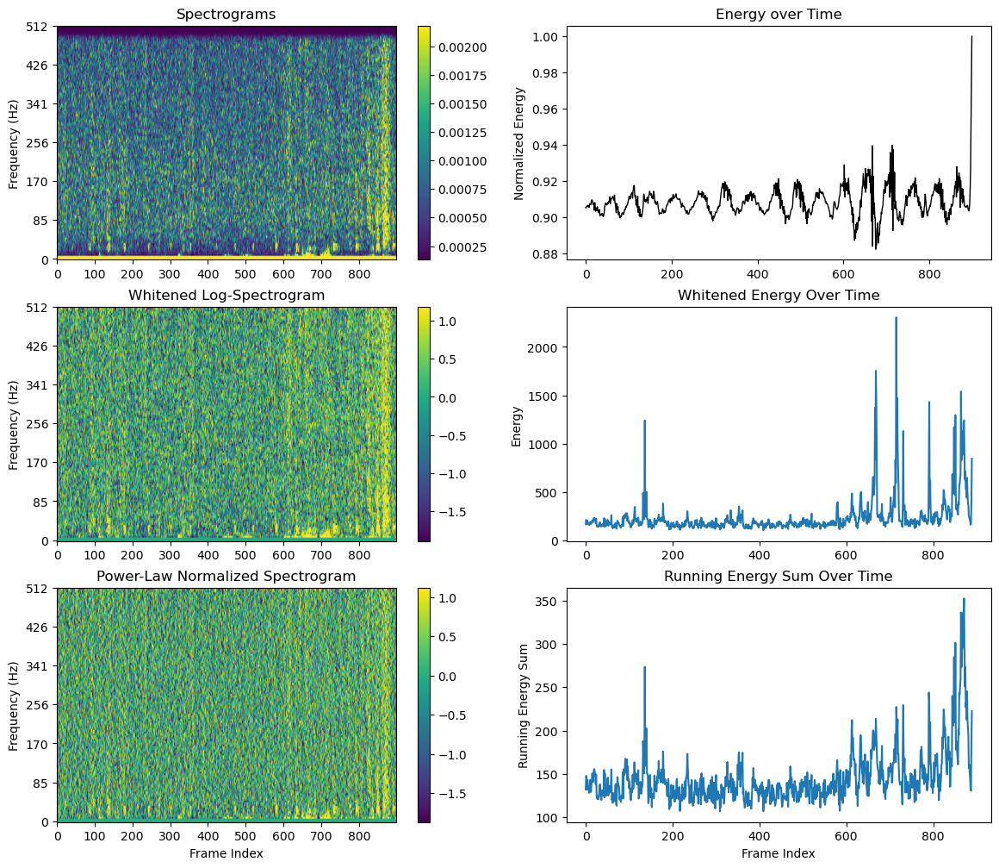

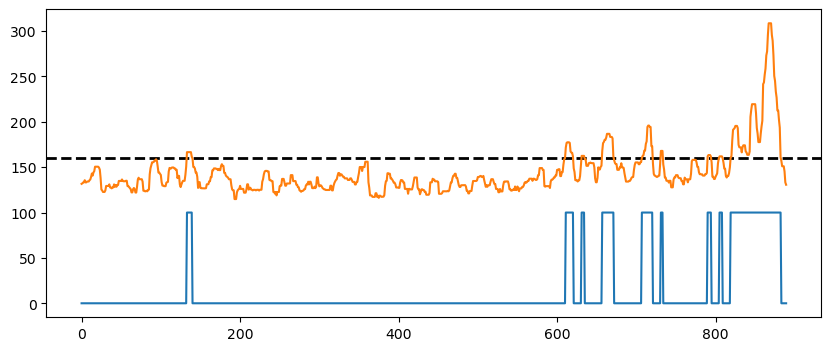

Filename: 1208221730.190501174246.wav


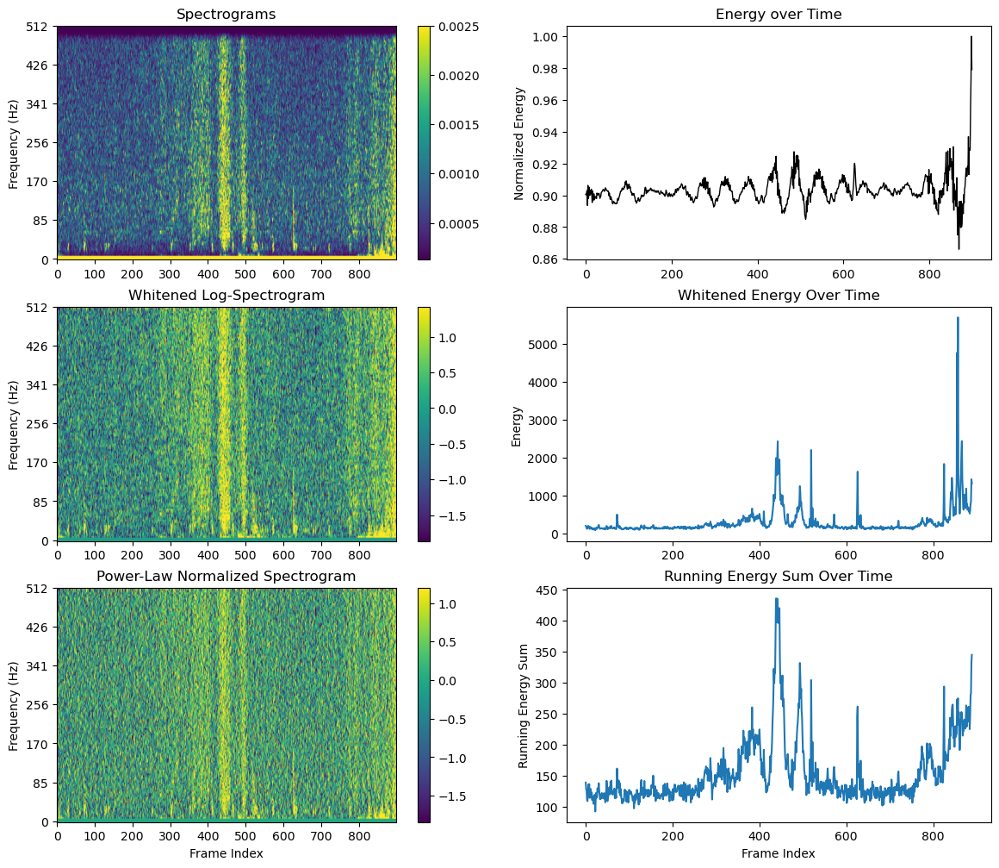

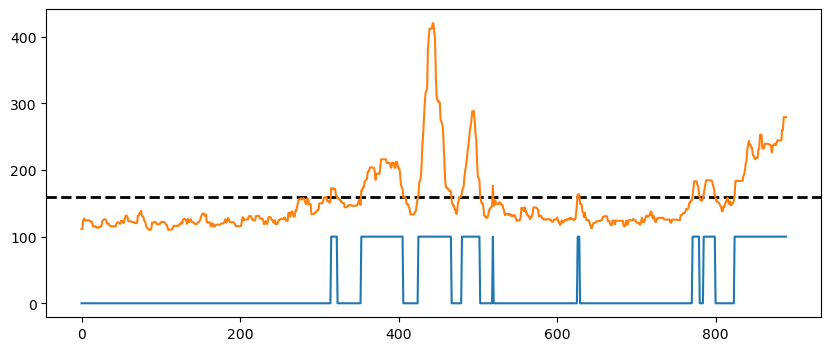

Filename: 1208221730.190501182246.wav


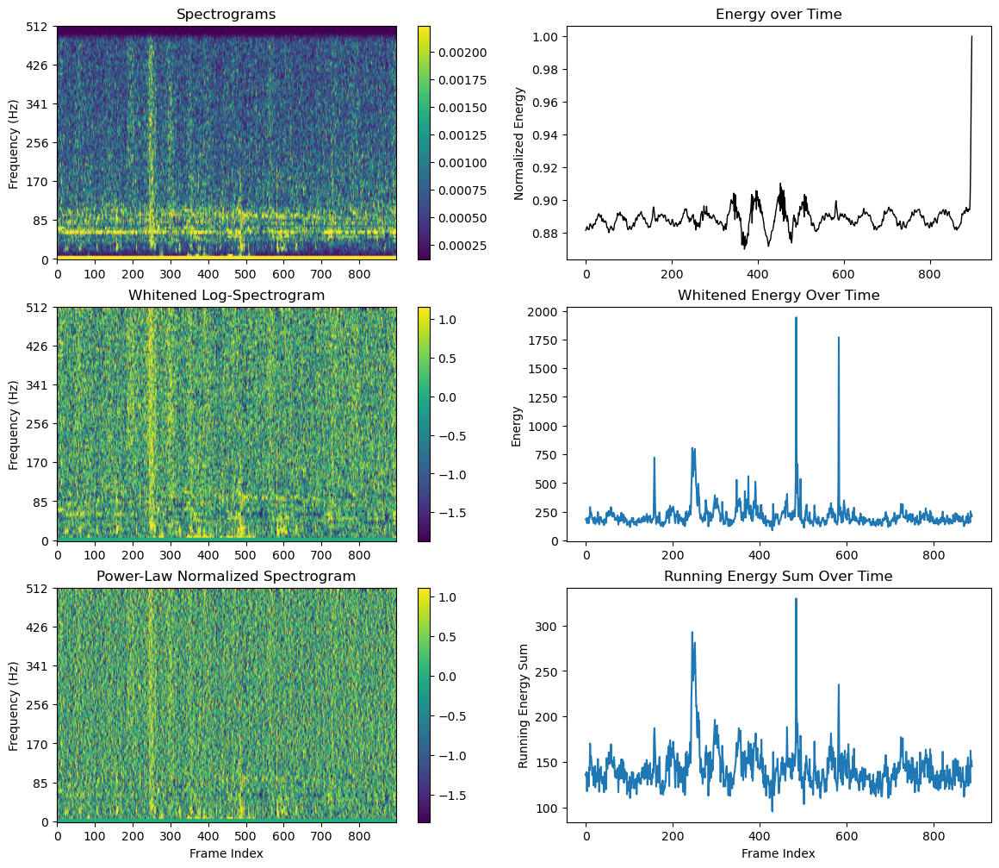

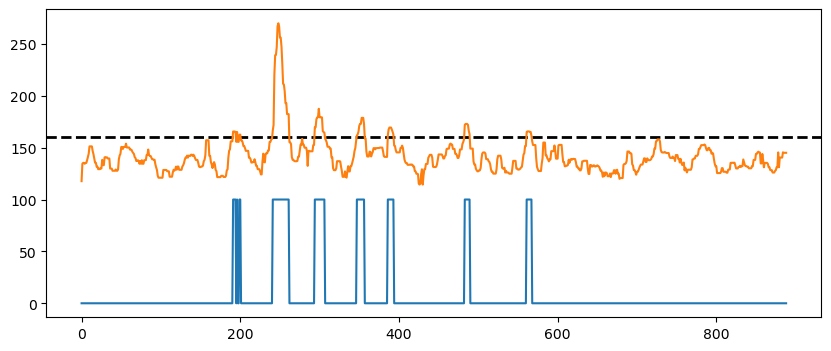

Filename: 1208221730.190501220246.wav


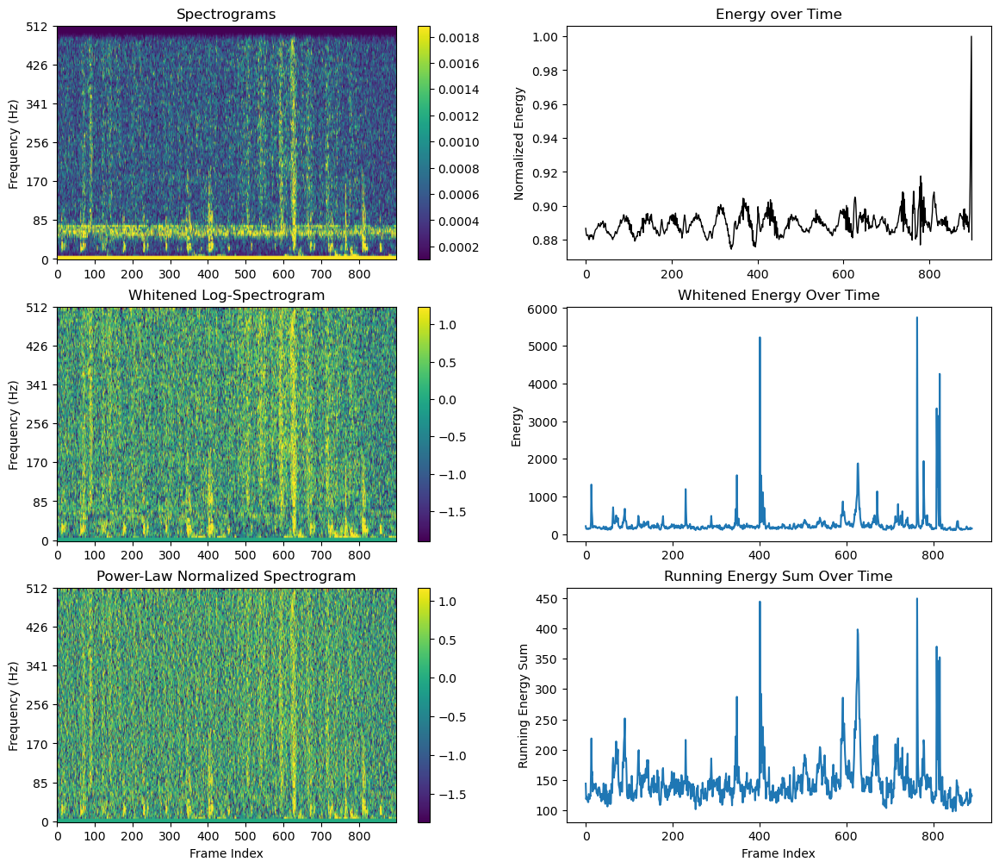

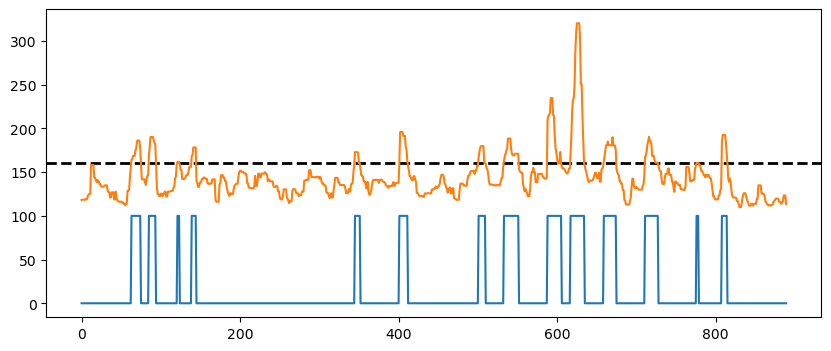

Filename: 1677774874.200124105615.wav


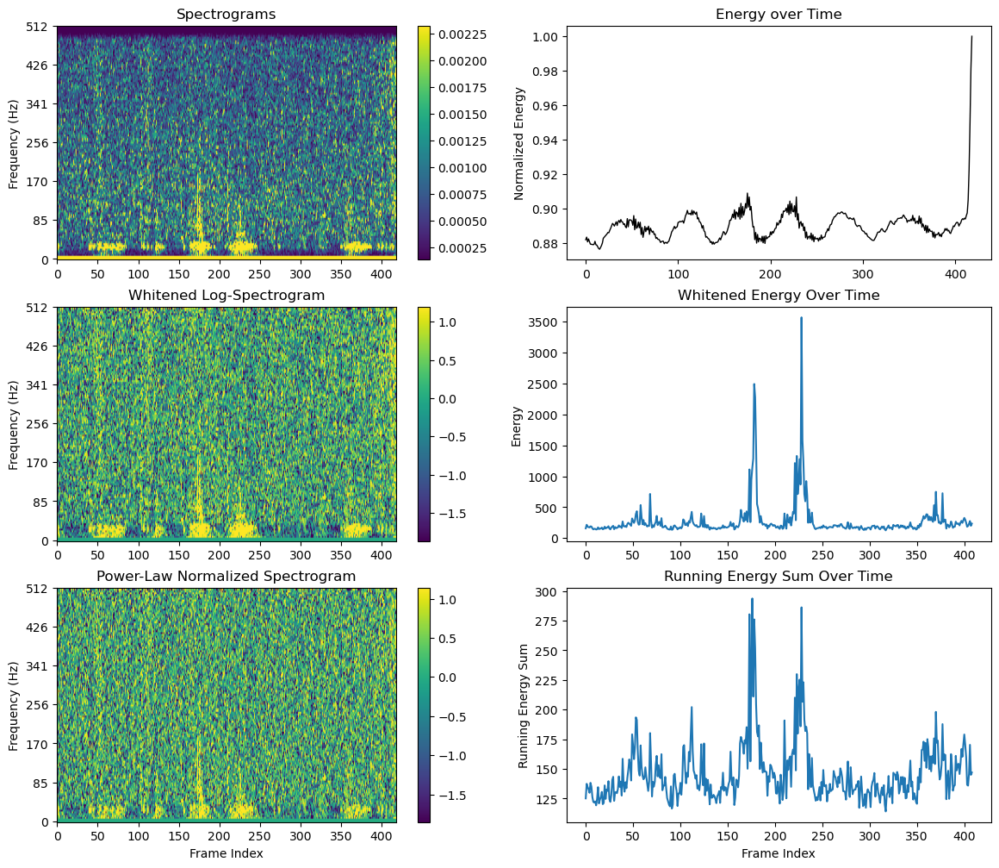

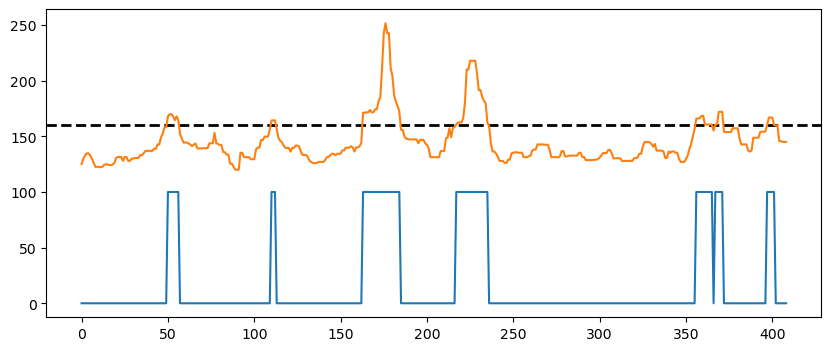

Filename: 1677774874.200124142615.wav


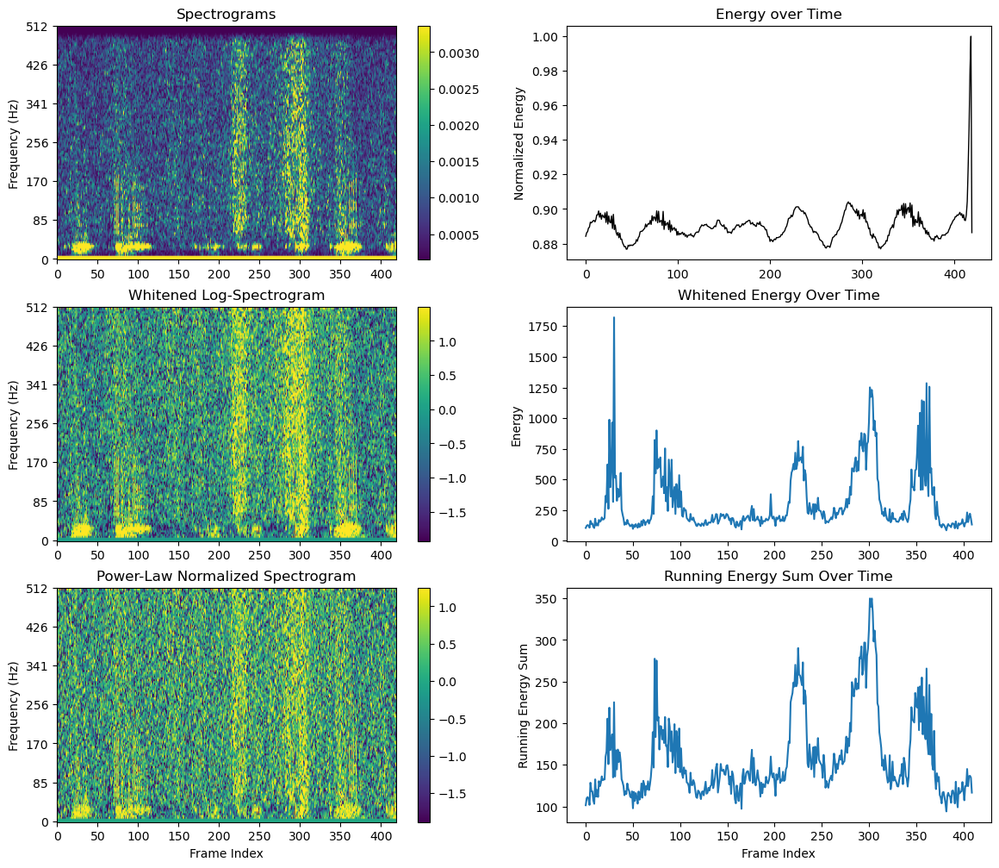

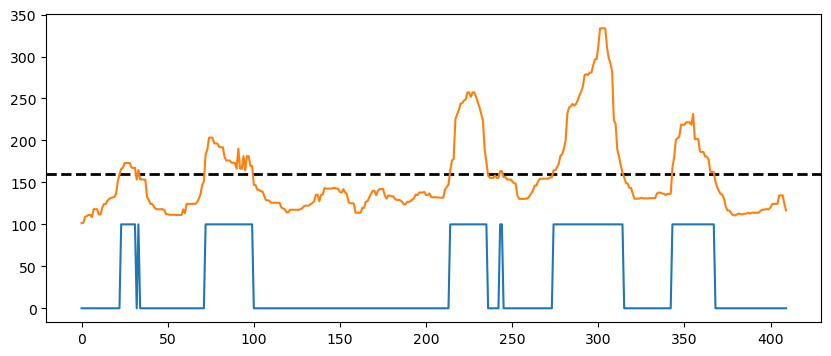

Filename: 1677774874.200124143615.wav


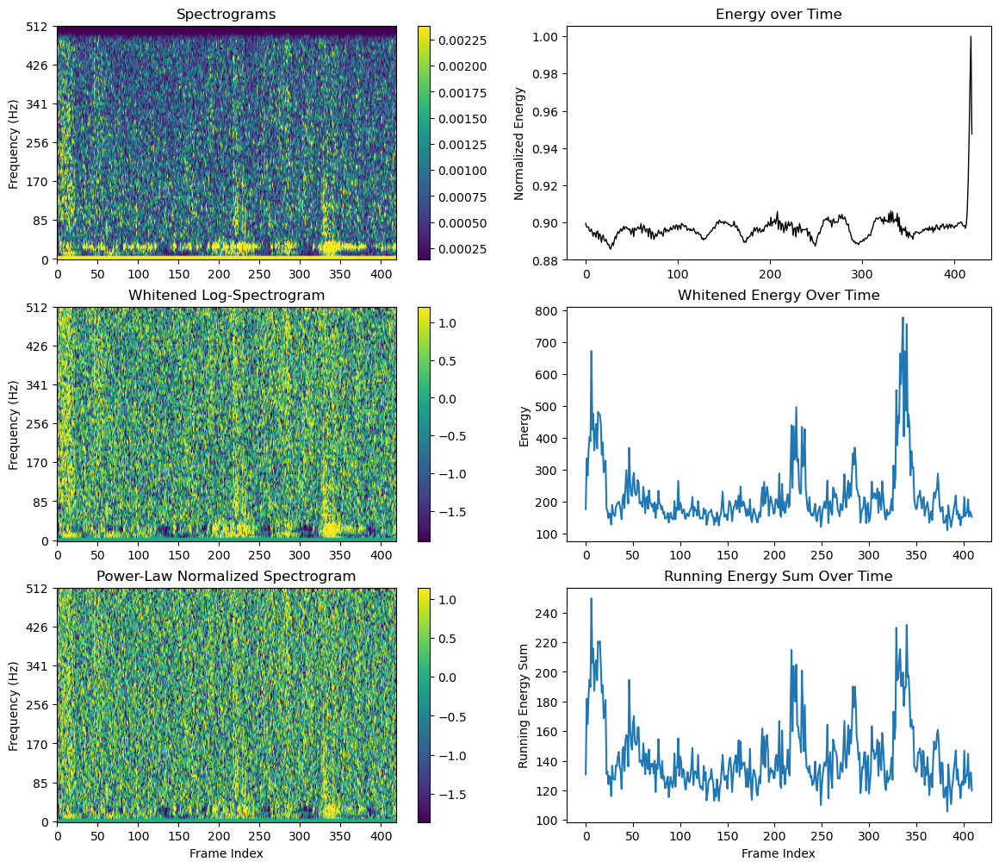

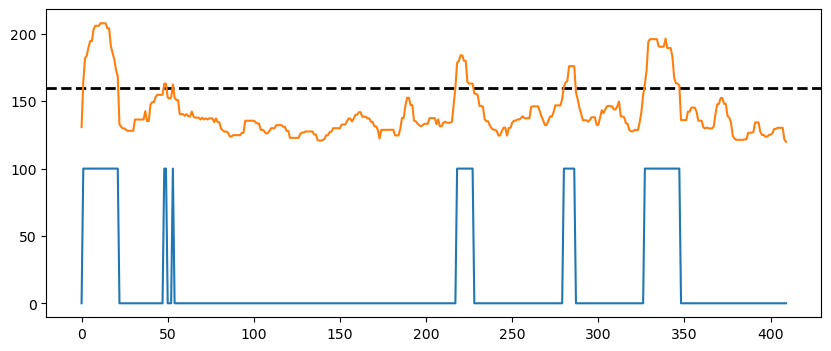

Filename: 1677774874.200124144615.wav


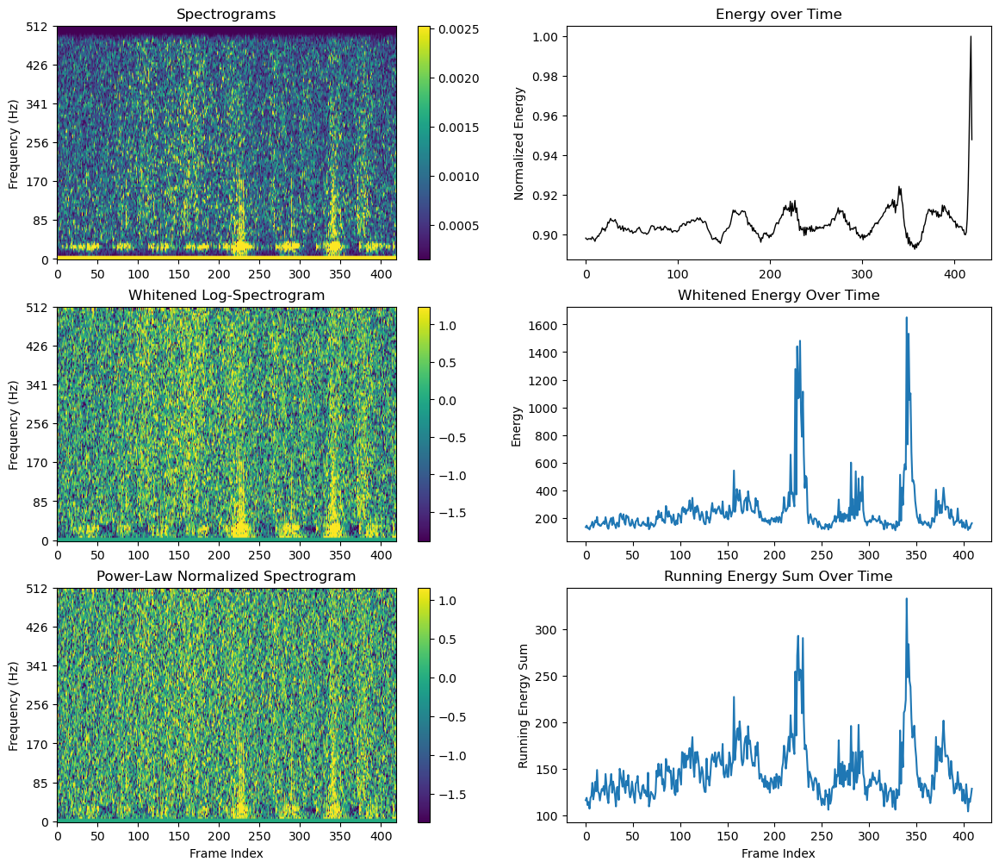

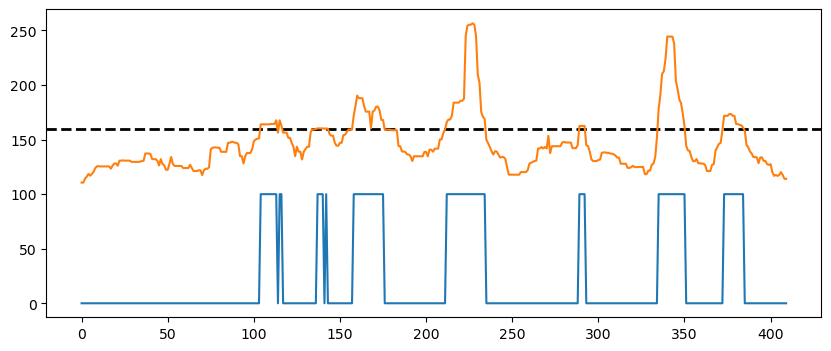

Filename: 1677774874.200124182615.wav


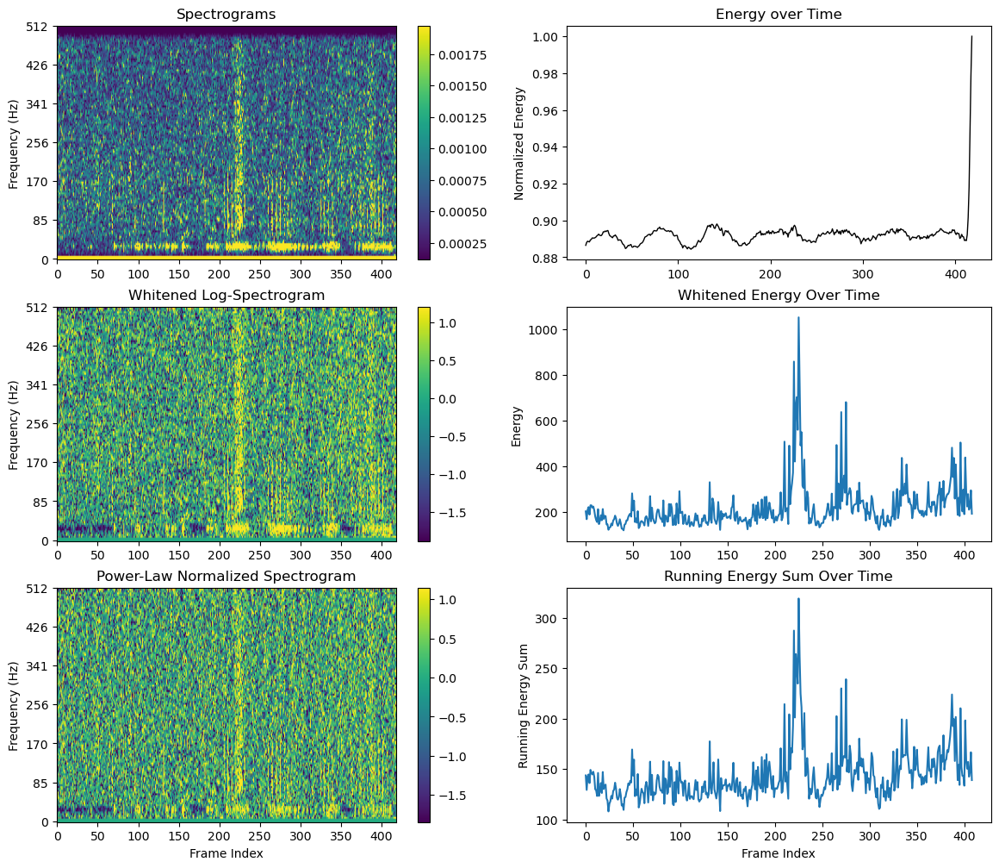

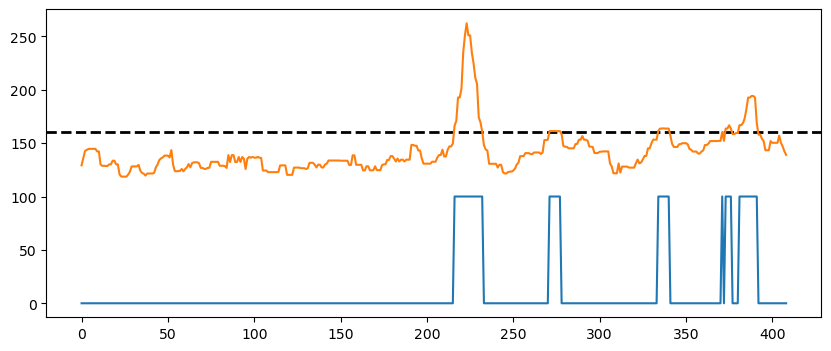

#########################   Category d     ###########################
Filename: 1677774874.191126074615.wav


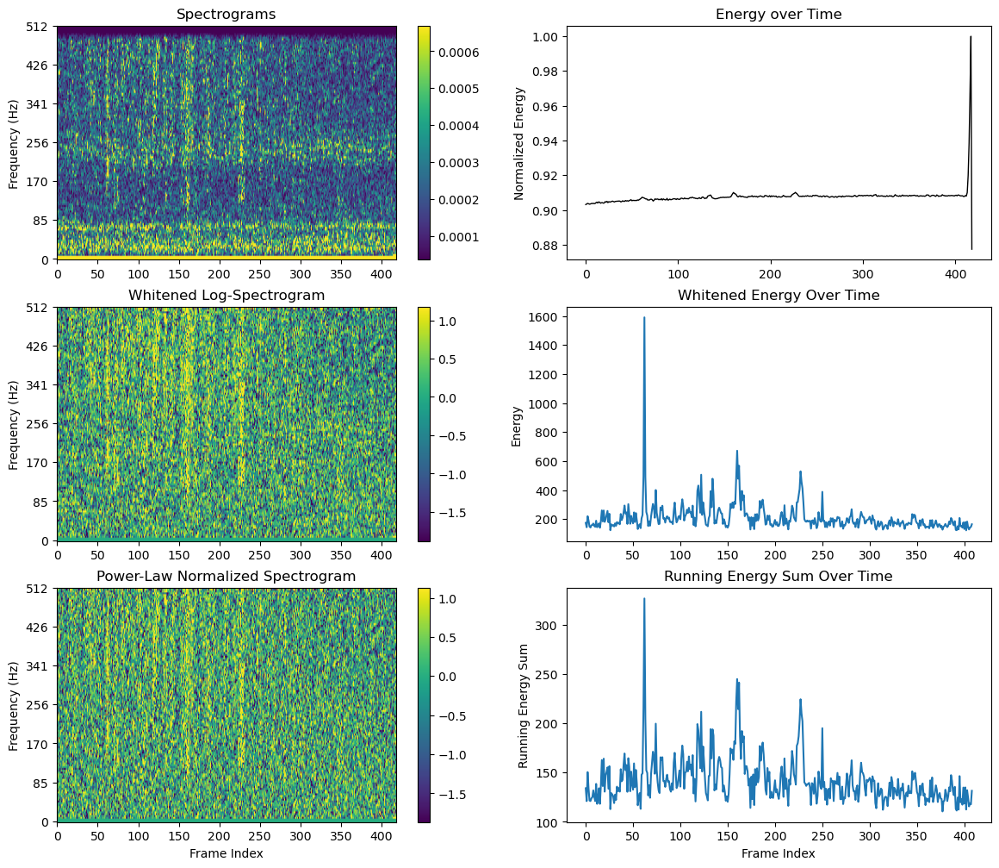

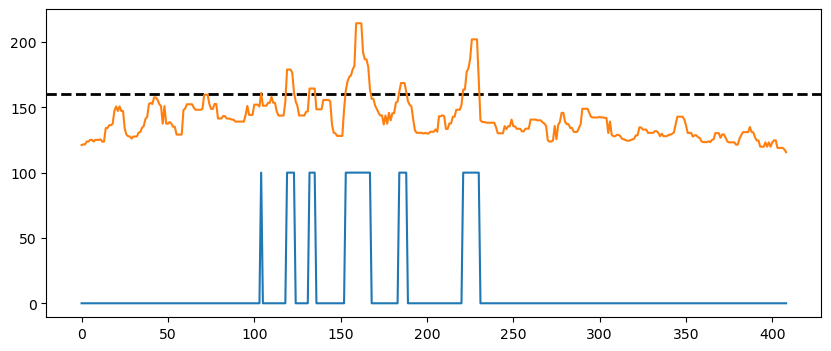

#########################   Category e     ###########################
Filename: 671633444.190617070024.wav


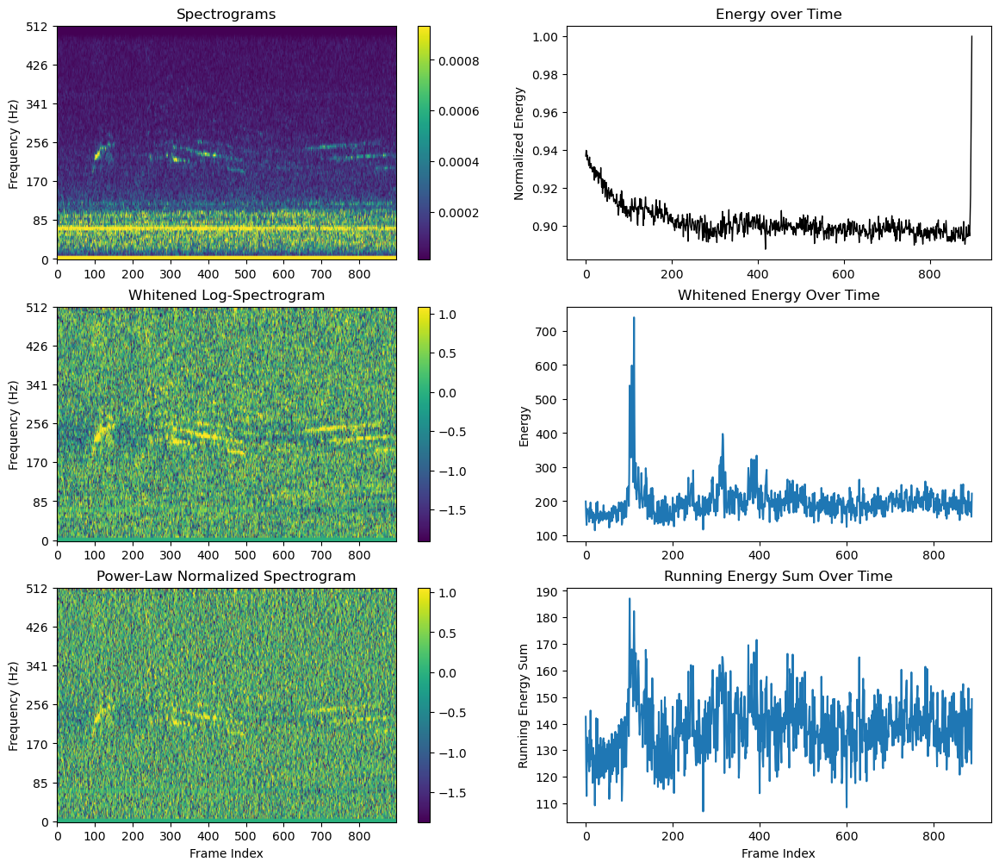

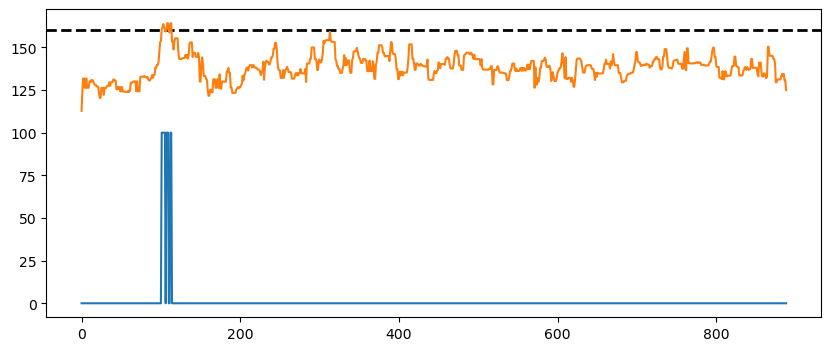

Filename: 671633444.190731074024.wav


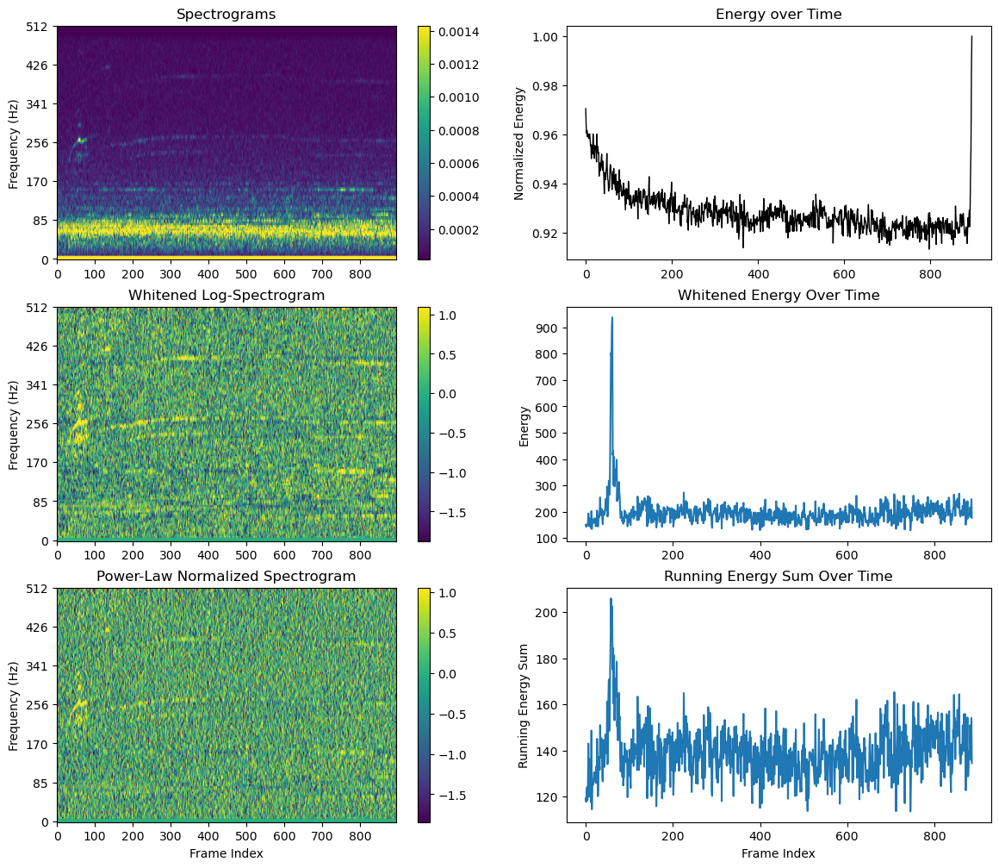

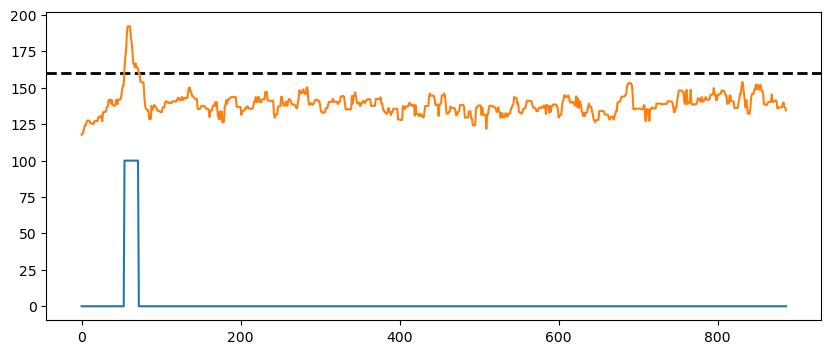

In [18]:
import os
import cv2

# fft length & O
import shutil

# Delete old snips directory if it exists
if os.path.exists("cnn_snips"):
    shutil.rmtree("cnn_snips")

    
#load one for demo
sr = 1024
hop_length = 128

trig = 160
all_trigger_rows = []
energy_dict = {}

for cat in df_PFS["category"][(df_PFS["category"].notna())].unique():
    file_paths = df_PFS[(df_PFS["Filename"].notna()) & (df_PFS["category"] == cat)]["Filename"].unique()
    print("#########################   Category " + cat+ "     ###########################")
   
    for fname in file_paths: 
        path = Path(fname)  # same directory, so just the name
        print("Filename: " + fname)
        # Step 1: load + resample
        y, _ = load_and_resample(str(path), target_sr=sr)
        
        # Step 2: frame
        # frames = frame_audio(y)
        # timestamps = frame_timestamps(len(frames), sr=sr)
        y_reduced = nr.reduce_noise(y=y, sr=sr, time_mask_smooth_ms = 320, prop_decrease = 0.20)
        X = spectrogram_encode(y_reduced, sr, hop_length = hop_length, n_fft = 256) #75% overlap, can play with it
        
        #throw out first 30 frames to avoid startup noise
        X = X[60:,:]
    
    
        fig, axes = plt.subplots(3, 2, figsize=(14, 12))

    
        # ---------------------
        # 5a
        #----------------------
        ax = axes[0, 0] 
        ylabels = np.linspace(0, sr/2, X.shape[1])
        vmin = np.percentile(X, 5)
        vmax = np.percentile(X, 95)
        
        im = ax.imshow(
            X.T,
            aspect='auto',
            vmin=vmin,
            vmax=vmax,
            cmap='viridis'
        )
        
        ax.invert_yaxis()
        ax.set_yticks(np.linspace(0, X.shape[1], 7))
        ax.set_yticklabels(np.linspace(0, sr/2, 7).astype(int))
        ax.set_ylabel("Frequency (Hz)")
        ax.set_title("Spectrograms")
        plt.colorbar(im, ax=ax)
    
        # ---------------------
        # 5b
        # ---------------------
        ax = axes[0, 1] 
        #energy vs time
        energy = np.sum(X**2, axis=1)
        
        # Optional: normalize for nicer plotting
        energy_norm = energy / (np.max(energy) + 1e-12)
        
        ax.plot(energy_norm, color='black', linewidth=1)
        ax.set_ylabel("Normalized Energy")
        ax.set_title("Energy over Time")
    
    
        # --------------------
        # 5c
        # --------------------
        ax = axes[1, 0]
        high_energy_threshold = np.percentile(energy, 90)
        low_energy_frames = energy < high_energy_threshold
        X_whitened = X / (np.median(X[low_energy_frames], axis=0) + 1e-10)  # add small value to avoid division by zero
    
        log_whitened = np.log2(X_whitened + 1e-12)
        
        # Compute contrast limits
        vmin = np.percentile(log_whitened, 5)
        vmax = np.percentile(log_whitened, 95)
        
        # Plot
        im = ax.imshow(
            log_whitened.T,
            aspect='auto',
            vmin=vmin,
            vmax=vmax,
            cmap='viridis'
        )
        
        ax.invert_yaxis()
        ax.set_yticks(np.linspace(0, X.shape[1], 7))
        plt.colorbar(im, ax=ax)
        ax.set_yticklabels(np.linspace(0, sr/2, 7).astype(int))
        ax.set_ylabel("Frequency (Hz)")
        ax.set_title("Whitened Log-Spectrogram")

    
    
        # ---------------------
        # 5d
        # ---------------------
        ax = axes[1, 1]
        #energy vs time
        energy = np.sum(X_whitened**2, axis=1)
        ax.plot(energy[:-10])
        ax.set_ylabel("Energy")
        ax.set_title("Whitened Energy Over Time")


    
        # -----------------------
        # 5e 
        # -----------------------
        ax = axes[2, 0]
        X_whitened_normalized = X_whitened / (np.max(X_whitened) + 1e-10)  # normalize to [0, 1]
        def power_law_transform(X, window = 20, alpha=1.0):
            #create running average of the spectrum
            X_avg = np.zeros_like(X)
            for i in range(X.shape[0]): #use wraparound or padding for edge effects
                start = max(0, i - window // 2)
                end = min(X.shape[0], i + window // 2 + 1)
                X_avg[i] = np.median(X[start:end], axis=0)
            #apply power law transform
            X_avg = np.maximum(X_avg, np.percentile(X_avg, 5))
            X_power_law = X / (X_avg + 1e-10) ** alpha  # add small value to avoid division by zero
            return X_power_law
    

        X_pl = power_law_transform(X_whitened, alpha=0.5)
        log_pl = np.log2(X_pl + 1e-12)
        
        im_pl = ax.imshow(
            log_pl.T,
            aspect='auto',
            vmin=np.percentile(log_pl, 5),
            vmax=np.percentile(log_pl, 95),
            cmap='viridis'
        )
        
        ax.invert_yaxis()
        ax.set_yticks(np.linspace(0, X.shape[1], 7))
        ax.set_yticklabels(np.linspace(0, sr/2, 7).astype(int))
        
        ax.set_xlabel("Frame Index")
        ax.set_ylabel("Frequency (Hz)")
        ax.set_title("Power-Law Normalized Spectrogram")

        plt.colorbar(im_pl, ax=ax)

        # -----------------------
        # 5f
        # -----------------------
        
        ax = axes[2, 1]
        
        #create running sum of energy across all frequencies
        energy_running_sum = (np.sum(X_whitened[:-10], axis=1)) # average energy per frame
        
        ax.plot(energy_running_sum)
        
        ax.set_xlabel("Frame Index")
        ax.set_ylabel("Running Energy Sum")
        ax.set_title("Running Energy Sum Over Time")
        
        # -----------------------
        # Other
        # -----------------------
    
        
        new_energy = scipy.signal.medfilt(energy_running_sum, 7)
        energy_dict[fname] = new_energy

        trigger = new_energy > trig
        intervals = extract_intervals(trigger)
        rows = []
        for start_f, end_f in intervals:
            rows.append({
                "Filename": fname,
                "Begin_Frame": start_f,
                "End_Frame": end_f,
                "Begin_Second": frame_to_seconds(start_f, sr, hop_length, 60),
                "End_Second": frame_to_seconds(end_f, sr, hop_length, 60)
            })
                    # Create output directory for CNN images
        os.makedirs("cnn_snips", exist_ok=True)
        os.makedirs(f"cnn_snips/{cat}", exist_ok=True)
        
        target_seconds = 4.0
        frames_per_second = sr / hop_length
        target_frames = int(target_seconds * frames_per_second)
        num_frames_total = log_pl.shape[0]
    
        for start_f, end_f in intervals:
            interval_length = end_f - start_f
            if interval_length > target_frames:
                num_chunks = interval_length // target_frames
                for i in range(int(num_chunks)):
                    chunk_st = start_f + i * target_frames
                    chunk_end = chunk_st + target_frames
                    # yield or save this chunk
                    snip = log_pl[int(chunk_st):int(chunk_end), :]
                    # do whatever you normally do with snip
            
                    snip_norm = (snip - snip.min()) / (snip.max() - snip.min() + 1e-12)
                                                
                    out_name = f"{Path(fname).stem}_{new_st_f}_{new_end_f}.png"
                    out_path = f"cnn_snips/{cat}/{out_name}"
                    cv2.imwrite(out_path, (snip_norm * 255).astype(np.uint8))
        
        
                continue  # skip padding logic
            needed_padding = (target_frames - interval_length)/2
            if (end_f + needed_padding <= num_frames_total) and (start_f - needed_padding >= 0):
                new_st_f = start_f - needed_padding
                new_end_f = end_f + needed_padding
            elif (end_f + needed_padding <= num_frames_total) and (start_f - needed_padding < 0):
                new_st_f = 0
                new_end_f = end_f + needed_padding + np.abs(start_f - needed_padding)
            elif (end_f + needed_padding > num_frames_total) and (start_f - needed_padding >= 0):
                new_st_f = start_f - needed_padding - (end_f + needed_padding - log_pl.shape[0])
                new_end_f = log_pl.shape[0]
            else: 
                print(f"Index out of bounds for file {fname}")
                continue
    
            new_st_f = int(round(new_st_f))
            new_end_f = int(round(new_end_f))
        
            new_st_f = max(0, new_st_f)
            new_end_f = min(num_frames_total, new_end_f)
        
            snip = log_pl[new_st_f:new_end_f, :]
    
            snip_norm = (snip - snip.min()) / (snip.max() - snip.min() + 1e-12)
                                        
            out_name = f"{Path(fname).stem}_{new_st_f}_{new_end_f}.png"
            out_path = f"cnn_snips/{cat}/{out_name}"
            cv2.imwrite(out_path, (snip_norm * 255).astype(np.uint8))
        
        
        df_events = pd.DataFrame(rows)
    
        
        # Save it for later
        all_trigger_rows.append(df_events)
    
        plt.figure(figsize=(10, 4))
        plt.plot(trigger * 100)
        plt.axhline(y=160, color='black', linestyle='--', linewidth=2, label="Threshold = 160")
        plt.plot(new_energy)
        plt.subplots_adjust(
            hspace=50,   # vertical spacing between rows
            wspace=0.35    # horizontal spacing between columns
        )

    
        plt.show()
    

df_all_triggers = pd.concat(all_trigger_rows, ignore_index=True)

## Other Stuff

* run on other files, see if effective

In [9]:
df_all_triggers[df_all_triggers["Filename"] == "1208221730.181207232246.wav"]

,Filename,Begin_Frame,End_Frame,Begin_Second,End_Second
63,1208221730.181207232246.wav,208,211,33.500,33.875
64,1208221730.181207232246.wav,299,301,44.875,45.125
65,1208221730.181207232246.wav,329,396,48.625,57.000
66,1208221730.181207232246.wav,411,414,58.875,59.250
67,1208221730.181207232246.wav,461,462,65.125,65.250
68,1208221730.181207232246.wav,503,504,70.375,70.500
69,1208221730.181207232246.wav,581,588,80.125,81.000
70,1208221730.181207232246.wav,689,694,93.625,94.250
71,1208221730.181207232246.wav,703,706,95.375,95.750
72,1208221730.181207232246.wav,797,806,107.125,108.250
